AI-BASED CATARACT DETECTION SYSTEM
Step 1: Environment Setup, Data Exploration, and Medical Insights

----------------------------------------------------------------------
DATASET STRUCTURE
----------------------------------------------------------------------

Split             Cataract     Normal      Total        Ratio
---------------------------------------------------------
Train                  595       2529       3124       1:4.25
Validation             124        548        672       1:4.42
Test                   123        545        668       1:4.43
---------------------------------------------------------
TOTAL                  842       3622       4464       1:4.30

Class Weights (for handling imbalance):
  Cataract: 4.25
  Normal:   1.0

----------------------------------------------------------------------
DATASET SOURCE ANALYSIS
----------------------------------------------------------------------

Source                 Cataract     Normal      Total   Percentage  C

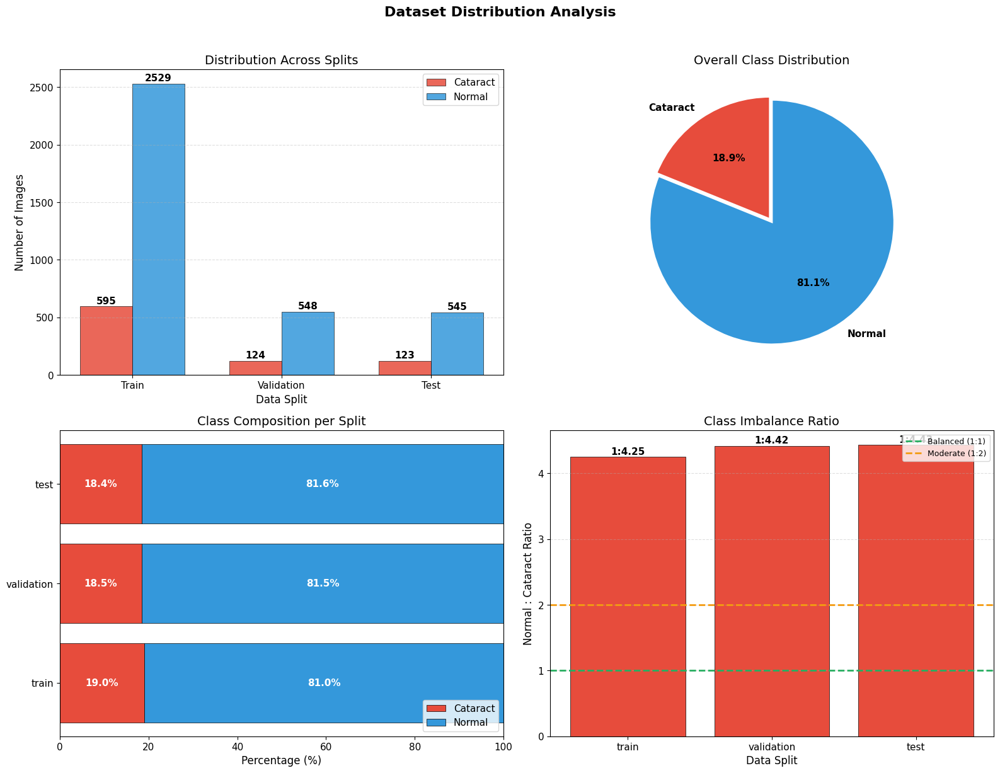


Visualization saved: dataset_distribution.png

----------------------------------------------------------------------
SAMPLE IMAGE ANALYSIS
----------------------------------------------------------------------


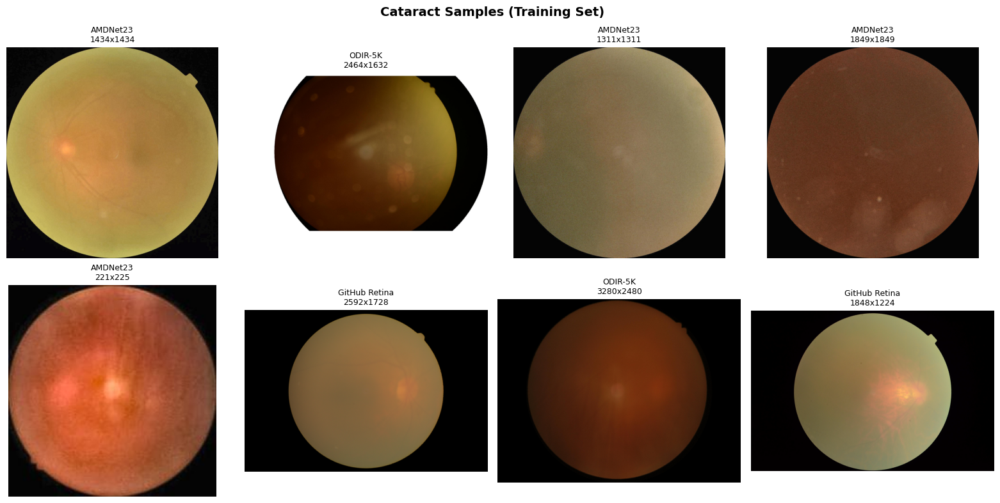

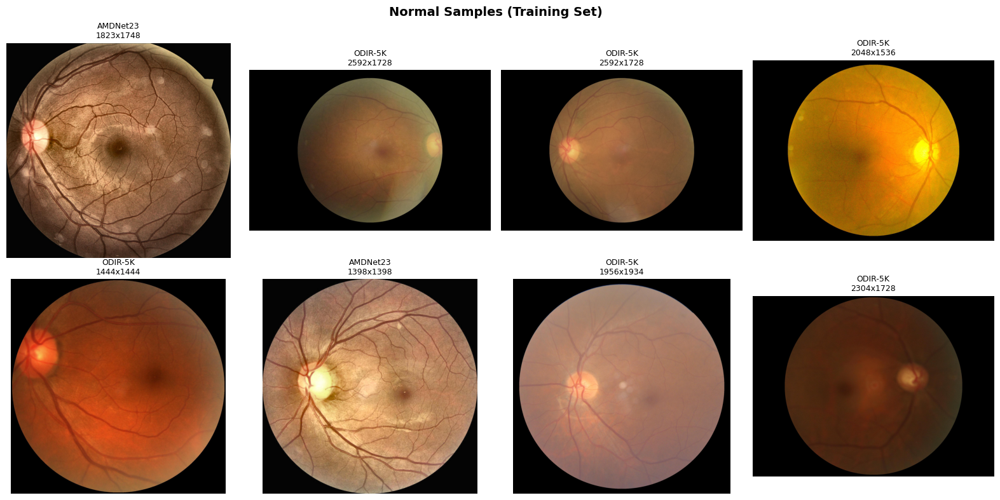


Sample visualizations saved.

----------------------------------------------------------------------
MEDICAL FEATURE ANALYSIS
----------------------------------------------------------------------


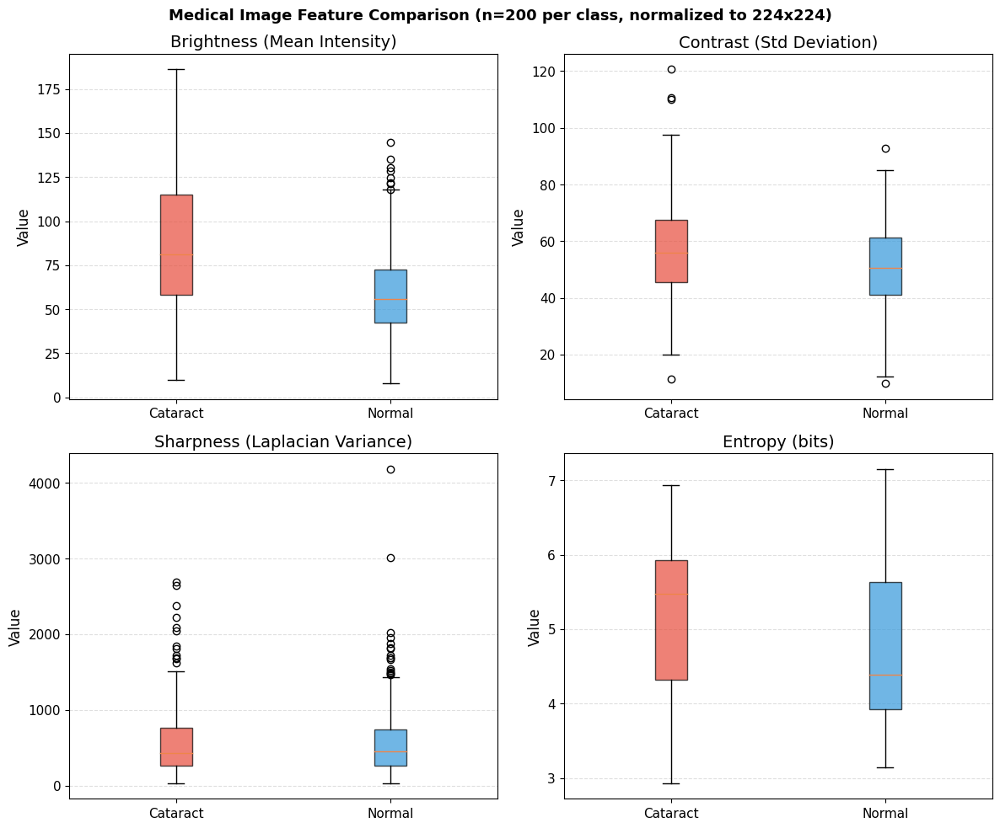


Feature                 Cataract (mean±std)      Normal (mean±std)   Difference
----------------------------------------------------------------------------
Brightness                    87.19 ± 38.94          60.17 ± 26.68       +27.03
Contrast                      57.33 ± 18.70          50.70 ± 15.26        +6.63
Sharpness                   594.20 ± 493.37        606.89 ± 535.04       -12.69
Entropy                         5.19 ± 0.94            4.76 ± 1.02        +0.44

Key Observations:
  - Cataract images are less sharp (-12.69), consistent with lens opacity causing blur.
  - Contrast: cataract > normal (+6.63). Possible dataset heterogeneity.
  - Cataract images are brighter (+27.03), possibly due to light scattering from opacified lens.
  - Entropy: cataract > normal (+0.44). Investigate source-level variation.

----------------------------------------------------------------------
PER-SOURCE FEATURE ANALYSIS
---------------------------------------------------------------------

In [1]:
# ============================================================================
# AI-BASED CATARACT DETECTION SYSTEM
# Step 1: Environment Setup, Data Exploration
# ============================================================================

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from collections import defaultdict

warnings.filterwarnings('ignore')

# Visualization settings
plt.style.use('default')
sns.set_palette("muted")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

np.random.seed(42)

print("=" * 70)
print("AI-BASED CATARACT DETECTION SYSTEM")
print("Step 1: Environment Setup, Data Exploration, and Medical Insights")
print("=" * 70)

# ============================================================================
# CONFIGURATION
# ============================================================================

DATASET_PATH = "/kaggle/input/datasets/sonartori/cataract-dataset/dataset"

# Dataset source information (from merged datasets)
DATASET_SOURCES = {
    'odir': {'name': 'ODIR-5K', 'prefix': 'odir_'},
    'amdnet': {'name': 'AMDNet23', 'prefix': 'amdnet_'},
    'github': {'name': 'GitHub Retina', 'prefix': 'github_'}
}


# ============================================================================
# DATASET EXPLORATION
# ============================================================================

def explore_dataset_structure():
    """Explore dataset structure and count images."""
    
    print("\n" + "-" * 70)
    print("DATASET STRUCTURE")
    print("-" * 70)
    
    if not os.path.exists(DATASET_PATH):
        print(f"Error: Dataset not found at {DATASET_PATH}")
        return {}, 0
    
    splits = ['train', 'validation', 'test']
    classes = ['cataract', 'normal']
    dataset_info = {}
    total_images = 0
    
    for split in splits:
        dataset_info[split] = {}
        for cls in classes:
            folder_path = os.path.join(DATASET_PATH, split, cls)
            if os.path.exists(folder_path):
                files = [f for f in os.listdir(folder_path)
                        if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
                count = len(files)
            else:
                count = 0
            dataset_info[split][cls] = count
            total_images += count
    
    # Print distribution
    print(f"\n{'Split':<15} {'Cataract':>10} {'Normal':>10} {'Total':>10} {'Ratio':>12}")
    print("-" * 57)
    
    for split in splits:
        cat = dataset_info[split]['cataract']
        norm = dataset_info[split]['normal']
        total = cat + norm
        ratio = f"1:{norm/cat:.2f}" if cat > 0 else "N/A"
        print(f"{split.capitalize():<15} {cat:>10} {norm:>10} {total:>10} {ratio:>12}")
    
    print("-" * 57)
    total_cat = sum(dataset_info[s]['cataract'] for s in splits)
    total_norm = sum(dataset_info[s]['normal'] for s in splits)
    overall_ratio = f"1:{total_norm/total_cat:.2f}" if total_cat > 0 else "N/A"
    print(f"{'TOTAL':<15} {total_cat:>10} {total_norm:>10} {total_images:>10} {overall_ratio:>12}")
    
    # Calculate class weights
    if total_cat > 0 and total_norm > 0:
        train_cat = dataset_info['train']['cataract']
        train_norm = dataset_info['train']['normal']
        train_total = train_cat + train_norm
        
        weight_cat = train_total / (2 * train_cat)
        weight_norm = train_total / (2 * train_norm)
        min_weight = min(weight_cat, weight_norm)
        
        class_weights = {
            'cataract': round(weight_cat / min_weight, 3),
            'normal': round(weight_norm / min_weight, 3)
        }
        
        dataset_info['class_weights'] = class_weights
        
        print(f"\nClass Weights (for handling imbalance):")
        print(f"  Cataract: {class_weights['cataract']}")
        print(f"  Normal:   {class_weights['normal']}")
    
    return dataset_info, total_images


def analyze_dataset_sources():
    
    print("\n" + "-" * 70)
    print("DATASET SOURCE ANALYSIS")
    print("-" * 70)
    
    source_counts = {source: {'cataract': 0, 'normal': 0} for source in DATASET_SOURCES}
    source_counts['other'] = {'cataract': 0, 'normal': 0}
    
    splits = ['train', 'validation', 'test']
    
    for split in splits:
        for cls in ['cataract', 'normal']:
            folder_path = os.path.join(DATASET_PATH, split, cls)
            if not os.path.exists(folder_path):
                continue
            
            for filename in os.listdir(folder_path):
                if not filename.lower().endswith(('.jpg', '.png', '.jpeg')):
                    continue
                
                identified = False
                for source, info in DATASET_SOURCES.items():
                    if filename.lower().startswith(info['prefix']):
                        source_counts[source][cls] += 1
                        identified = True
                        break
                
                if not identified:
                    source_counts['other'][cls] += 1
    
    total_all = sum(source_counts[s]['cataract'] + source_counts[s]['normal']
                    for s in source_counts)
    
    print(f"\n{'Source':<20} {'Cataract':>10} {'Normal':>10} {'Total':>10} {'Percentage':>12} {'Cat:Norm Ratio':>15}")
    print("-" * 77)
    
    for source in list(DATASET_SOURCES.keys()) + ['other']:
        counts = source_counts[source]
        total = counts['cataract'] + counts['normal']
        if total == 0:
            continue
        
        pct = (total / total_all * 100) if total_all > 0 else 0
        source_name = DATASET_SOURCES.get(source, {}).get('name', 'Other')
        
        if counts['cataract'] > 0:
            ratio = f"1:{counts['normal']/counts['cataract']:.2f}"
        else:
            ratio = "N/A"
        
        print(f"{source_name:<20} {counts['cataract']:>10} {counts['normal']:>10} "
              f"{total:>10} {pct:>11.1f}% {ratio:>15}")
    
    other_total = source_counts['other']['cataract'] + source_counts['other']['normal']
    if other_total > 0:
        print(f"\nWARNING: {other_total} images could not be identified by source prefix.")
        print("Check DATASET_SOURCES prefix values.")
    
    return source_counts

def analyze_image_properties():
    """Analyze image dimensions and formats."""
    
    print("\n" + "-" * 70)
    print("IMAGE PROPERTIES")
    print("-" * 70)
    
    properties = {
        'cataract': {'widths': [], 'heights': [], 'formats': []},
        'normal': {'widths': [], 'heights': [], 'formats': []}
    }
    
    sample_size = 50
    
    for cls in ['cataract', 'normal']:
        folder = os.path.join(DATASET_PATH, 'train', cls)
        if not os.path.exists(folder):
            continue
        
        files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
        sample_files = np.random.choice(files, min(sample_size, len(files)), replace=False)
        
        for f in sample_files:
            img_path = os.path.join(folder, f)
            img = cv2.imread(img_path)
            
            if img is not None:
                h, w = img.shape[:2]
                properties[cls]['widths'].append(w)
                properties[cls]['heights'].append(h)
                properties[cls]['formats'].append(f.split('.')[-1].lower())
    
    # Print statistics
    for cls in ['cataract', 'normal']:
        if properties[cls]['widths']:
            print(f"\n{cls.upper()} Images (n={len(properties[cls]['widths'])}):")
            print(f"  Width:  min={min(properties[cls]['widths'])}, "
                  f"max={max(properties[cls]['widths'])}, "
                  f"mean={np.mean(properties[cls]['widths']):.0f}")
            print(f"  Height: min={min(properties[cls]['heights'])}, "
                  f"max={max(properties[cls]['heights'])}, "
                  f"mean={np.mean(properties[cls]['heights']):.0f}")
            format_counts = pd.Series(properties[cls]['formats']).value_counts()
            print(f"  Formats: {dict(format_counts)}")
    
    return properties


def create_dataset_visualizations(dataset_info):
    """Create dataset distribution visualizations."""
    
    print("\n" + "-" * 70)
    print("GENERATING VISUALIZATIONS")
    print("-" * 70)
    
    splits = ['train', 'validation', 'test']
    cataract_data = [dataset_info[split]['cataract'] for split in splits]
    normal_data = [dataset_info[split]['normal'] for split in splits]
    
    color_cataract = '#E74C3C'
    color_normal = '#3498DB'
    
    fig = plt.figure(figsize=(16, 12))
    fig.suptitle("Dataset Distribution Analysis", fontsize=16, fontweight='bold', y=1.02)
    
    # Plot 1: Bar chart
    ax1 = fig.add_subplot(2, 2, 1)
    x = np.arange(len(splits))
    width = 0.35
    
    bars1 = ax1.bar(x - width/2, cataract_data, width, label='Cataract', 
                    color=color_cataract, alpha=0.85, edgecolor='black', linewidth=0.5)
    bars2 = ax1.bar(x + width/2, normal_data, width, label='Normal', 
                    color=color_normal, alpha=0.85, edgecolor='black', linewidth=0.5)
    
    ax1.set_xlabel('Data Split')
    ax1.set_ylabel('Number of Images')
    ax1.set_title('Distribution Across Splits')
    ax1.set_xticks(x)
    ax1.set_xticklabels([s.capitalize() for s in splits])
    ax1.legend()
    ax1.grid(axis='y', linestyle='--', alpha=0.4)
    
    for bar in bars1:
        height = bar.get_height()
        ax1.annotate(f'{int(height)}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontweight='bold')
    for bar in bars2:
        height = bar.get_height()
        ax1.annotate(f'{int(height)}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontweight='bold')
    
    # Plot 2: Pie chart
    ax2 = fig.add_subplot(2, 2, 2)
    total_cat = sum(cataract_data)
    total_norm = sum(normal_data)
    
    wedges, texts, autotexts = ax2.pie(
        [total_cat, total_norm],
        labels=['Cataract', 'Normal'],
        autopct='%1.1f%%',
        colors=[color_cataract, color_normal],
        explode=(0.03, 0),
        startangle=90,
        textprops={'fontsize': 11, 'fontweight': 'bold'},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    ax2.set_title('Overall Class Distribution')
    
    # Plot 3: Stacked bar
    ax3 = fig.add_subplot(2, 2, 3)
    totals = [c + n for c, n in zip(cataract_data, normal_data)]
    cat_pct = [c/t*100 if t > 0 else 0 for c, t in zip(cataract_data, totals)]
    norm_pct = [n/t*100 if t > 0 else 0 for n, t in zip(normal_data, totals)]
    
    ax3.barh(splits, cat_pct, label='Cataract', color=color_cataract, edgecolor='black', linewidth=0.5)
    ax3.barh(splits, norm_pct, left=cat_pct, label='Normal', color=color_normal, edgecolor='black', linewidth=0.5)
    
    ax3.set_xlabel('Percentage (%)')
    ax3.set_title('Class Composition per Split')
    ax3.legend(loc='lower right')
    ax3.set_xlim(0, 100)
    
    for i, (c, n) in enumerate(zip(cat_pct, norm_pct)):
        if c > 10:
            ax3.text(c/2, i, f'{c:.1f}%', ha='center', va='center', fontweight='bold', color='white')
        if n > 10:
            ax3.text(c + n/2, i, f'{n:.1f}%', ha='center', va='center', fontweight='bold', color='white')
    
    # Plot 4: Imbalance ratio
    ax4 = fig.add_subplot(2, 2, 4)
    ratios = [n/c if c > 0 else 0 for c, n in zip(cataract_data, normal_data)]
    
    bar_colors = ['#27AE60' if r <= 1.5 else '#F39C12' if r <= 2.5 else '#E74C3C' for r in ratios]
    
    bars = ax4.bar(splits, ratios, color=bar_colors, edgecolor='black', linewidth=0.5)
    ax4.axhline(y=1, color='#27AE60', linestyle='--', linewidth=2, label='Balanced (1:1)')
    ax4.axhline(y=2, color='#F39C12', linestyle='--', linewidth=2, label='Moderate (1:2)')
    
    ax4.set_xlabel('Data Split')
    ax4.set_ylabel('Normal : Cataract Ratio')
    ax4.set_title('Class Imbalance Ratio')
    ax4.legend(loc='upper right', fontsize=9)
    ax4.grid(axis='y', linestyle='--', alpha=0.4)
    
    for bar, ratio in zip(bars, ratios):
        height = bar.get_height()
        ax4.annotate(f'1:{ratio:.2f}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontweight='bold')
    
    plt.tight_layout()
    plt.savefig('dataset_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("\nVisualization saved: dataset_distribution.png")


def analyze_sample_images():
    """Load and display sample images."""
    
    print("\n" + "-" * 70)
    print("SAMPLE IMAGE ANALYSIS")
    print("-" * 70)
    
    sample_images = {'cataract': [], 'normal': []}
    sample_info = {'cataract': [], 'normal': []}
    
    for cls in ['cataract', 'normal']:
        folder = os.path.join(DATASET_PATH, 'train', cls)
        if not os.path.exists(folder):
            continue
        
        files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
        sample_files = np.random.choice(files, min(8, len(files)), replace=False)
        
        for f in sample_files:
            img_path = os.path.join(folder, f)
            img = cv2.imread(img_path)
            
            if img is not None:
                img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                sample_images[cls].append(img_rgb)
                
                source = 'Unknown'
                for src, info in DATASET_SOURCES.items():
                    if f.lower().startswith(info['prefix']):
                        source = info['name']
                        break
                
                sample_info[cls].append({
                    'filename': f,
                    'source': source,
                    'size': f"{img.shape[1]}x{img.shape[0]}"
                })
    
    # Plot cataract samples
    if sample_images['cataract']:
        fig, axes = plt.subplots(2, 4, figsize=(16, 8))
        fig.suptitle("Cataract Samples (Training Set)", fontsize=14, fontweight='bold')
        
        for i, (img, info) in enumerate(zip(sample_images['cataract'][:8], sample_info['cataract'][:8])):
            row, col = divmod(i, 4)
            axes[row, col].imshow(img)
            axes[row, col].set_title(f"{info['source']}\n{info['size']}", fontsize=9)
            axes[row, col].axis('off')
        
        plt.tight_layout()
        plt.savefig('cataract_samples.png', dpi=150, bbox_inches='tight')
        plt.show()
    
    # Plot normal samples
    if sample_images['normal']:
        fig, axes = plt.subplots(2, 4, figsize=(16, 8))
        fig.suptitle("Normal Samples (Training Set)", fontsize=14, fontweight='bold')
        
        for i, (img, info) in enumerate(zip(sample_images['normal'][:8], sample_info['normal'][:8])):
            row, col = divmod(i, 4)
            axes[row, col].imshow(img)
            axes[row, col].set_title(f"{info['source']}\n{info['size']}", fontsize=9)
            axes[row, col].axis('off')
        
        plt.tight_layout()
        plt.savefig('normal_samples.png', dpi=150, bbox_inches='tight')
        plt.show()
    
    print("\nSample visualizations saved.")
    
    return sample_images, sample_info


def medical_feature_analysis():

    print("\n" + "-" * 70)
    print("MEDICAL FEATURE ANALYSIS")
    print("-" * 70)

    features = {
        'cataract': {'brightness': [], 'contrast': [], 'sharpness': [], 'entropy': []},
        'normal':   {'brightness': [], 'contrast': [], 'sharpness': [], 'entropy': []}
    }

    sample_size = 200

    for cls in ['cataract', 'normal']:
        folder = os.path.join(DATASET_PATH, 'train', cls)
        if not os.path.exists(folder):
            continue

        files = [f for f in os.listdir(folder)
                 if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
        
        selected = np.random.choice(files, min(sample_size, len(files)), replace=False)

        for f in selected:
            img_path = os.path.join(folder, f)
            img = cv2.imread(img_path)

            if img is None:
                continue

            # Resize to fixed size before feature extraction
            img_resized = cv2.resize(img, (224, 224))
            gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

            # Brightness
            features[cls]['brightness'].append(np.mean(gray))

            # Contrast
            features[cls]['contrast'].append(np.std(gray))

            # Sharpness - size-normalized (both images are 224x224 now)
            laplacian = cv2.Laplacian(gray, cv2.CV_64F)
            features[cls]['sharpness'].append(laplacian.var())

            # Entropy
            hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
            hist = hist / hist.sum()
            hist = hist[hist > 0]
            entropy = -np.sum(hist * np.log2(hist))
            features[cls]['entropy'].append(entropy)

    # Visualization
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    fig.suptitle("Medical Image Feature Comparison (n=200 per class, normalized to 224x224)",
                 fontsize=13, fontweight='bold')

    feature_names = ['brightness', 'contrast', 'sharpness', 'entropy']
    titles = ['Brightness (Mean Intensity)', 'Contrast (Std Deviation)',
              'Sharpness (Laplacian Variance)', 'Entropy (bits)']

    color_cataract = '#E74C3C'
    color_normal = '#3498DB'

    for idx, (feature, title) in enumerate(zip(feature_names, titles)):
        row, col = divmod(idx, 2)
        ax = axes[row, col]

        cat_data = features['cataract'][feature]
        norm_data = features['normal'][feature]

        bp = ax.boxplot([cat_data, norm_data], labels=['Cataract', 'Normal'], patch_artist=True)
        bp['boxes'][0].set_facecolor(color_cataract)
        bp['boxes'][1].set_facecolor(color_normal)
        bp['boxes'][0].set_alpha(0.7)
        bp['boxes'][1].set_alpha(0.7)

        ax.set_title(title)
        ax.set_ylabel('Value')
        ax.grid(axis='y', linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.savefig('medical_features.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Stats table with mean and std
    print(f"\n{'Feature':<20} {'Cataract (mean±std)':>22} {'Normal (mean±std)':>22} {'Difference':>12}")
    print("-" * 76)

    for feature in feature_names:
        cat_vals = features['cataract'][feature]
        norm_vals = features['normal'][feature]

        cat_mean, cat_std   = np.mean(cat_vals), np.std(cat_vals)
        norm_mean, norm_std = np.mean(norm_vals), np.std(norm_vals)
        diff = cat_mean - norm_mean

        cat_str  = f"{cat_mean:.2f} ± {cat_std:.2f}"
        norm_str = f"{norm_mean:.2f} ± {norm_std:.2f}"

        print(f"{feature.capitalize():<20} {cat_str:>22} {norm_str:>22} {diff:>+12.2f}")

    # Conclusions with correct directional logic
    print("\nKey Observations:")

    sharpness_diff  = np.mean(features['cataract']['sharpness'])  - np.mean(features['normal']['sharpness'])
    contrast_diff   = np.mean(features['cataract']['contrast'])   - np.mean(features['normal']['contrast'])
    brightness_diff = np.mean(features['cataract']['brightness']) - np.mean(features['normal']['brightness'])
    entropy_diff    = np.mean(features['cataract']['entropy'])    - np.mean(features['normal']['entropy'])

    if sharpness_diff < 0:
        print(f"  - Cataract images are less sharp ({sharpness_diff:.2f}), "
              f"consistent with lens opacity causing blur.")
    else:
        print(f"  - Sharpness: cataract > normal ({sharpness_diff:+.2f}). "
              f"Check dataset quality or source-level bias.")

    if contrast_diff < 0:
        print(f"  - Cataract images have lower contrast ({contrast_diff:.2f}), "
              f"indicating reduced structural definition.")
    else:
        print(f"  - Contrast: cataract > normal ({contrast_diff:+.2f}). "
              f"Possible dataset heterogeneity.")

    if brightness_diff > 0:
        print(f"  - Cataract images are brighter (+{brightness_diff:.2f}), "
              f"possibly due to light scattering from opacified lens.")
    else:
        print(f"  - Cataract images are darker ({brightness_diff:.2f}), "
              f"possibly due to reduced light transmission.")

    if entropy_diff < 0:
        print(f"  - Cataract images have lower entropy ({entropy_diff:.2f}), "
              f"suggesting less texture detail due to haziness.")
    else:
        print(f"  - Entropy: cataract > normal ({entropy_diff:+.2f}). "
              f"Investigate source-level variation.")

    return features

def per_source_feature_analysis():

    print("\n" + "-" * 70)
    print("PER-SOURCE FEATURE ANALYSIS")
    print("-" * 70)

    source_features = {}

    for source, info in DATASET_SOURCES.items():
        source_features[source] = {
            'cataract': {'sharpness': [], 'contrast': [], 'brightness': []},
            'normal':   {'sharpness': [], 'contrast': [], 'brightness': []}
        }

    sample_size = 100

    for cls in ['cataract', 'normal']:
        folder = os.path.join(DATASET_PATH, 'train', cls)
        if not os.path.exists(folder):
            continue

        files = [f for f in os.listdir(folder)
                 if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

        for filename in files:
            source_key = None
            for source, info in DATASET_SOURCES.items():
                if filename.lower().startswith(info['prefix']):
                    source_key = source
                    break

            if source_key is None:
                continue

            # Per source sample limit
            current_count = len(source_features[source_key][cls]['sharpness'])
            if current_count >= sample_size:
                continue

            img_path = os.path.join(DATASET_PATH, 'train', cls, filename)
            img = cv2.imread(img_path)

            if img is None:
                continue

            img_resized = cv2.resize(img, (224, 224))
            gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

            laplacian = cv2.Laplacian(gray, cv2.CV_64F)

            source_features[source_key][cls]['sharpness'].append(laplacian.var())
            source_features[source_key][cls]['contrast'].append(np.std(gray))
            source_features[source_key][cls]['brightness'].append(np.mean(gray))

    # Print table per source
    for feature in ['brightness', 'contrast', 'sharpness']:
        print(f"\n{feature.upper()}")
        print(f"  {'Source':<20} {'Cataract (mean±std)':>22} {'Normal (mean±std)':>22} {'Diff':>10}")
        print("  " + "-" * 74)

        for source, info in DATASET_SOURCES.items():
            cat_vals  = source_features[source]['cataract'][feature]
            norm_vals = source_features[source]['normal'][feature]

            if not cat_vals or not norm_vals:
                continue

            cat_mean,  cat_std  = np.mean(cat_vals),  np.std(cat_vals)
            norm_mean, norm_std = np.mean(norm_vals), np.std(norm_vals)
            diff = cat_mean - norm_mean

            cat_str  = f"{cat_mean:.2f} ± {cat_std:.2f}"
            norm_str = f"{norm_mean:.2f} ± {norm_std:.2f}"

            print(f"  {info['name']:<20} {cat_str:>22} {norm_str:>22} {diff:>+10.2f}")

    return source_features
    
def print_summary(dataset_info, total_images):
    """Print summary of Step 1."""
    
    print("\n" + "=" * 70)
    print("STEP 1 SUMMARY")
    print("=" * 70)
    
    total_cat = sum(dataset_info[s]['cataract'] for s in ['train', 'validation', 'test'])
    total_norm = sum(dataset_info[s]['normal'] for s in ['train', 'validation', 'test'])
    
    print(f"""
    Dataset Overview:
      Total Images:       {total_images}
      Training Set:       {dataset_info['train']['cataract'] + dataset_info['train']['normal']}
      Validation Set:     {dataset_info['validation']['cataract'] + dataset_info['validation']['normal']}
      Test Set:           {dataset_info['test']['cataract'] + dataset_info['test']['normal']}
    
    Class Distribution:
      Cataract:           {total_cat} ({total_cat/total_images*100:.1f}%)
      Normal:             {total_norm} ({total_norm/total_images*100:.1f}%)
    
    Data Sources:         ODIR-5K, AMDNet23, GitHub Retina
    Split Ratio:          70% / 15% / 15%
    """)
    
    if 'class_weights' in dataset_info:
        print(f"    Class Weights:")
        print(f"      Cataract:         {dataset_info['class_weights']['cataract']}")
        print(f"      Normal:           {dataset_info['class_weights']['normal']}")
    
    print("\n    Saved Outputs:")
    print("      - dataset_distribution.png")
    print("      - cataract_samples.png")
    print("      - normal_samples.png")
    print("      - medical_features.png")
    
    print("\n" + "=" * 70)
    print("Step 1 Complete. Ready for Step 2: Preprocessing")
    print("=" * 70)


# ============================================================================
# MAIN EXECUTION
# ============================================================================

# Run all analysis steps
dataset_info, total_images = explore_dataset_structure()

if dataset_info and total_images > 0:
    source_counts    = analyze_dataset_sources()
    image_properties = analyze_image_properties()
    create_dataset_visualizations(dataset_info)
    sample_images, sample_info = analyze_sample_images()
    features = medical_feature_analysis()          
    source_features = per_source_feature_analysis() 
    print_summary(dataset_info, total_images)
else:
    print(f"\nError: Dataset not found at {DATASET_PATH}")
    print("Please verify the dataset path and try again.")

AI-BASED CATARACT DETECTION SYSTEM
Step 2: Duplicate Detection + Offline Augmentation + Preprocessing + DataLoader

Configuration:
  Image Size       : 224x224
  Batch Size       : 32
  CLAHE            : True
  Ben Graham       : True
  Weighted Sampler : True (auto-checks after aug)
  Hash Threshold   : 0.98
  Cataract Target  : 3000
  Sources          : ['ODIR-5K', 'AMDNet23', 'GitHub Retina']

----------------------------------------------------------------------
CREATING DATASETS & DATALOADERS
----------------------------------------------------------------------


----------------------------------------------------------------------
DUPLICATE DETECTION
----------------------------------------------------------------------

Total images found : 4464
Computing pHash...


100%|██████████| 4464/4464 [02:32<00:00, 29.18it/s]


Scanning 4464 images for duplicates...


100%|██████████| 9/9 [00:02<00:00,  3.48it/s]



Mixed-class duplicates : 0
Cross-split duplicates : 21

Cross-split pairs (higher-priority split kept):
  REMOVE: amdnet_img_0461.jpg                      (test)
  KEEP  : amdnet_cataract_021.jpg                  (train)   sim=0.992
  REMOVE: amdnet_img_0533.jpg                      (validation)
  KEEP  : amdnet_Copy of img_0533.jpg              (train)   sim=1.000
  REMOVE: amdnet_cataract_047.jpg                  (validation)
  KEEP  : amdnet_Copy of cataract_047.jpg          (train)   sim=1.000
  REMOVE: amdnet_Copy of img_0501.jpg              (validation)
  KEEP  : amdnet_cataract_061.jpg                  (train)   sim=0.992
  REMOVE: amdnet_Copy of img_0501.jpg              (validation)
  KEEP  : amdnet_img_0501.jpg                      (train)   sim=1.000
  REMOVE: amdnet_Copy of 2109_right.jpg            (test)
  KEEP  : amdnet_2109_right.jpg                    (train)   sim=1.000
  REMOVE: amdnet_cataract_083.jpg                  (validation)
  KEEP  : amdnet_Copy of cataract

 81%|████████  | 481/595 [01:04<00:15,  7.42it/s]



  Generated                 : 2405
  Total train cataract      : 3000

  Post-augmentation class weights:
    Cataract : 1.0
    Normal   : 1.186

         Train:  5529 images | Cataract: 3000 | Normal: 2529
    Validation:   665 images | Cataract: 117 | Normal: 548
          Test:   656 images | Cataract: 113 | Normal: 543

  Train set source breakdown:
    Augmented           : 2405
    ODIR-5K             : 2144
    AMDNet23            : 700
    GitHub Retina       : 280

  Train loader: shuffle=True, sampler OFF  (cataract ratio=54.3% — balanced)

----------------------------------------------------------------------
PREPROCESSING PIPELINE VISUALIZATION
----------------------------------------------------------------------


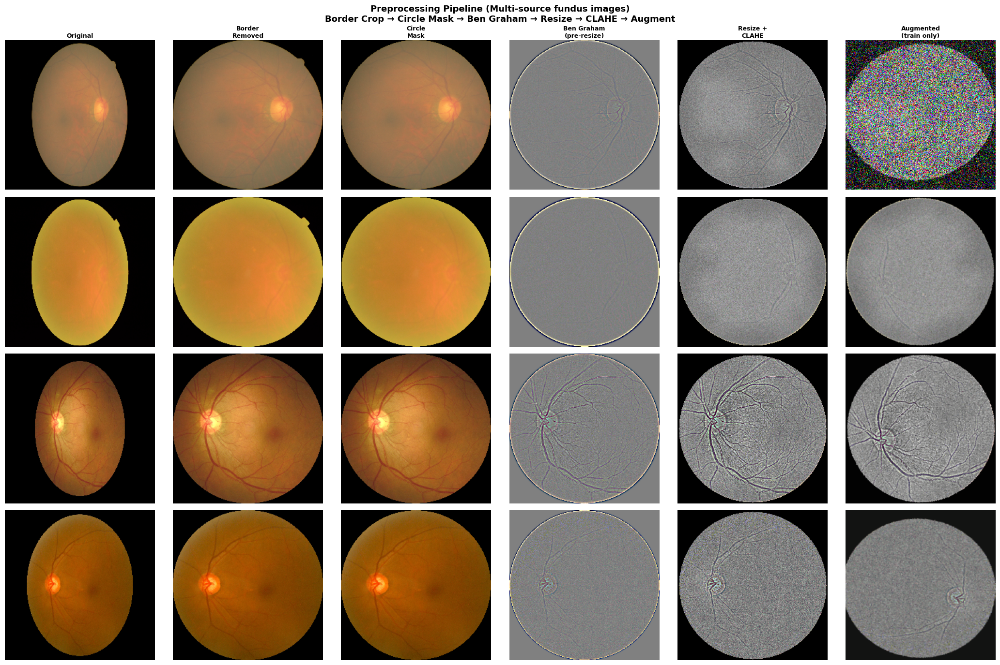

  Saved: preprocessing_pipeline.png

----------------------------------------------------------------------
AUGMENTATION EFFECT VISUALIZATION
----------------------------------------------------------------------


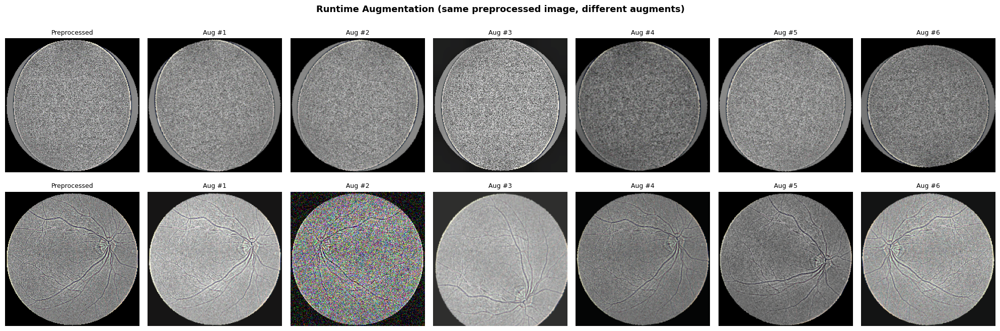

  Saved: augmentation_effect.png

----------------------------------------------------------------------
DATALOADER VERIFICATION
----------------------------------------------------------------------

         Train: Cataract=2987 | Normal=2517 | Cat%=54.3%

    Validation: Cataract=117 | Normal=548 | Cat%=17.6%

          Test: Cataract=113 | Normal=543 | Cat%=17.2%


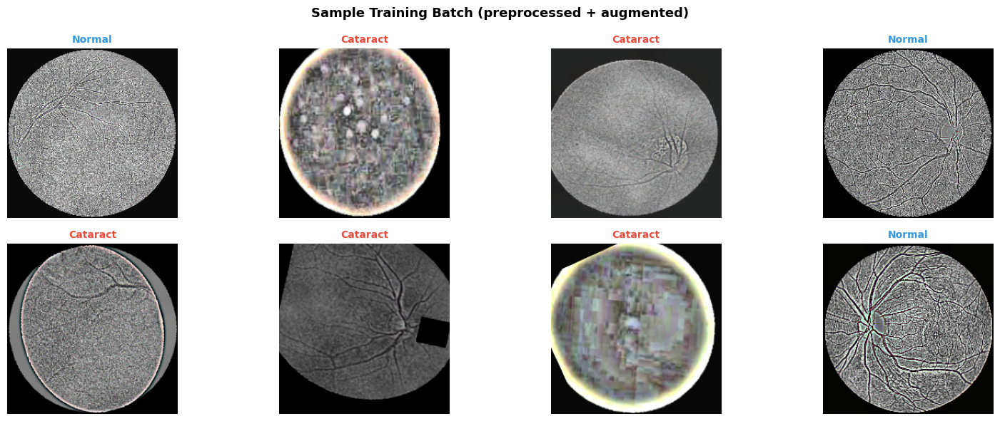

  Saved: batch_verification.png

----------------------------------------------------------------------
WEIGHTED SAMPLER EFFECT ANALYSIS
----------------------------------------------------------------------

  Batches analyzed          : 20
  Original cataract ratio   : 54.3%
  WeightedSampler per-batch : 51.7% (std=6.0%)
  Status                    : Balanced


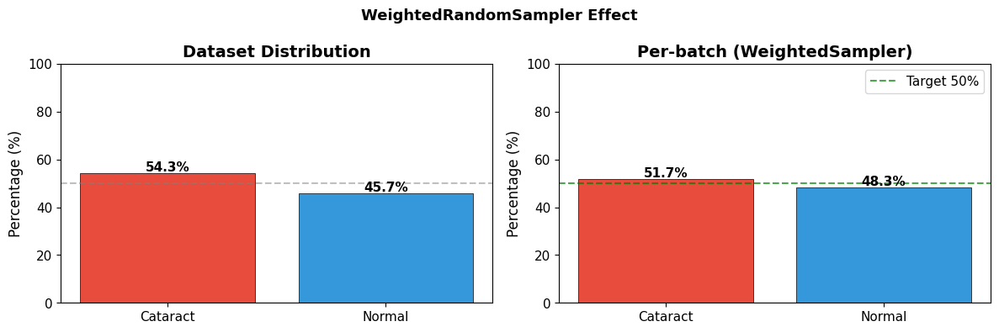

  Saved: sampler_effect.png

STEP 2 SUMMARY

  Duplicate Detection:
    Mixed-class / cross-split duplicates removed : 19

  Offline Augmentation (train/cataract only):
    Original train cataract    : 595
    After augmentation         : 3000
    Train normal               : 2529
    Train cataract ratio       : 54.3%

  Final Split Sizes:
    Train      :  5529  (Cataract: 3000, Normal: 2529)
    Validation :   665  (Cataract: 117, Normal: 548)
    Test       :   656  (Cataract: 113, Normal: 543)

  Preprocessing Pipeline (multi-source aware):
    1. Black Border Removal   → fundus region crop
    2. Circle Mask            → remove background
    3. Ben Graham             → inter-source illumination normalization (pre-resize)
    4. Resize LANCZOS4        → 224x224
    5. CLAHE (LAB space)      → contrast normalization (post-resize)
    6. Circle Mask            → clean edges

  Runtime Augmentation (train only, severity=medium):
    Flip (H/V), Rotate, ShiftScaleRotate
    Brightnes

In [2]:
# ============================================================================
# AI-BASED CATARACT DETECTION SYSTEM
# Step 2: Duplicate Detection + Offline Augmentation + Preprocessing + DataLoader
# Multi-source aware: ODIR-5K, AMDNet23, GitHub Retina
# ============================================================================

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
import time
from pathlib import Path
from scipy.fftpack import dct
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as transforms
from PIL import Image

import albumentations as A
from albumentations.pytorch import ToTensorV2

warnings.filterwarnings('ignore')

np.random.seed(42)
torch.manual_seed(42)

print("=" * 70)
print("AI-BASED CATARACT DETECTION SYSTEM")
print("Step 2: Duplicate Detection + Offline Augmentation + Preprocessing + DataLoader")
print("=" * 70)


# ============================================================================
# CONFIGURATION
# ============================================================================

CONFIG = {
    'dataset_path'         : '/kaggle/input/datasets/sonartori/cataract-dataset/dataset',
    'aug_save_dir'         : '/kaggle/working/augmented_cataract',
    'image_size'           : 224,
    'apply_clahe'          : True,
    'apply_ben_graham'     : True,
    'remove_black_border'  : True,
    'classes'              : ['cataract', 'normal'],
    'class_to_idx'         : {'cataract': 0, 'normal': 1},
    'mean'                 : [0.485, 0.456, 0.406],
    'std'                  : [0.229, 0.224, 0.225],
    'batch_size'           : 32,
    'num_workers'          : 2,
    'use_weighted_sampler' : True,
    'aug_severity'         : 'medium',
    'splits'               : ['train', 'validation', 'test'],
    'hash_size'            : 16,
    'hash_threshold'       : 0.98,    
    'cataract_target'      : 3000,    
    'source_prefixes' : {
        'ODIR-5K'      : 'odir_',
        'AMDNet23'     : 'amdnet_',
        'GitHub Retina': 'github_',
    },
}

print("\nConfiguration:")
print(f"  Image Size       : {CONFIG['image_size']}x{CONFIG['image_size']}")
print(f"  Batch Size       : {CONFIG['batch_size']}")
print(f"  CLAHE            : {CONFIG['apply_clahe']}")
print(f"  Ben Graham       : {CONFIG['apply_ben_graham']}")
print(f"  Weighted Sampler : {CONFIG['use_weighted_sampler']} (auto-checks after aug)")
print(f"  Hash Threshold   : {CONFIG['hash_threshold']}")
print(f"  Cataract Target  : {CONFIG['cataract_target']}")
print(f"  Sources          : {list(CONFIG['source_prefixes'].keys())}")


# ============================================================================
# DUPLICATE DETECTION
# ============================================================================

def compute_phash(img_path: str, hash_size: int):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    size    = hash_size * 4
    resized = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    dct_out = dct(dct(resized.T, norm='ortho').T, norm='ortho')
    dct_low = dct_out[:hash_size, :hash_size]
    return (dct_low > np.median(dct_low)).flatten()


def run_duplicate_detection(config: dict) -> set:
    print("\n" + "-" * 70)
    print("DUPLICATE DETECTION")
    print("-" * 70)

    registry = []
    for split in ['train', 'validation', 'test']:
        for label in ['cataract', 'normal']:
            folder = os.path.join(config['dataset_path'], split, label)
            if not os.path.exists(folder):
                continue
            for fname in os.listdir(folder):
                if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                    continue
                registry.append({
                    'path'  : os.path.join(folder, fname),
                    'split' : split,
                    'label' : label,
                    'fname' : fname,
                    'phash' : None,
                })

    print(f"\nTotal images found : {len(registry)}")
    print("Computing pHash...")

    valid_registry = []
    for entry in tqdm(registry):
        h = compute_phash(entry['path'], config['hash_size'])
        if h is not None:
            entry['phash'] = h
            valid_registry.append(entry)

    n       = len(valid_registry)
    hashes  = np.array([e['phash'] for e in valid_registry], dtype=np.bool_)

    print(f"Scanning {n} images for duplicates...")

    mixed_class    = []
    cross_split    = []
    split_priority = {'train': 0, 'validation': 1, 'test': 2}

    chunk_size = 500
    for i in tqdm(range(0, n, chunk_size)):
        chunk_end = min(i + chunk_size, n)

        for global_i in range(i, chunk_end):
            if global_i + 1 >= n:
                break

            h_i    = hashes[global_i]
            h_rest = hashes[global_i + 1:]

            diffs  = (h_i != h_rest).sum(axis=1)
            sims   = 1.0 - diffs / h_i.shape[0]

            matches = np.where(sims >= config['hash_threshold'])[0]

            for m in matches:
                global_j = global_i + 1 + m
                e1, e2   = valid_registry[global_i], valid_registry[global_j]

                if e1['split'] == e2['split'] and e1['label'] == e2['label']:
                    continue

                sim = float(sims[m])
                if e1['label'] != e2['label']:
                    mixed_class.append((e1, e2, sim))
                elif e1['split'] != e2['split']:
                    cross_split.append((e1, e2, sim))

    print(f"\nMixed-class duplicates : {len(mixed_class)}")
    print(f"Cross-split duplicates : {len(cross_split)}")

    paths_to_remove = set()

    if mixed_class:
        print("\nMixed-class pairs (both removed — label conflict):")
        for e1, e2, sim in mixed_class:
            print(f"  {e1['fname'][:40]:40s} ({e1['split']}/{e1['label']})")
            print(f"  {e2['fname'][:40]:40s} ({e2['split']}/{e2['label']})  sim={sim:.3f}")
            paths_to_remove.add(e1['path'])
            paths_to_remove.add(e2['path'])

    if cross_split:
        print("\nCross-split pairs (higher-priority split kept):")
        for e1, e2, sim in cross_split:
            remove = e1 if split_priority[e1['split']] > split_priority[e2['split']] else e2
            keep   = e2 if remove is e1 else e1
            print(f"  REMOVE: {remove['fname'][:40]:40s} ({remove['split']})")
            print(f"  KEEP  : {keep['fname'][:40]:40s} ({keep['split']})   sim={sim:.3f}")
            paths_to_remove.add(remove['path'])

    if not mixed_class and not cross_split:
        print("  No critical duplicates found.")

    print(f"\nTotal images flagged for removal : {len(paths_to_remove)}")
    return paths_to_remove


# ============================================================================
# FUNDUS PREPROCESSOR
# Multi-source aware: different cameras → illumination/resolution mismatch
# Pipeline order:
#   border crop → circle mask → Ben Graham → resize → CLAHE → circle mask
# ============================================================================

class FundusPreprocessor:

    def __init__(self, config):
        self.config      = config
        self.target_size = config['image_size']
        self.clahe       = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

    def remove_black_border(self, image):
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY) if len(image.shape) == 3 else image.copy()

        _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
        kernel    = np.ones((5, 5), np.uint8)
        thresh    = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)
        thresh    = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
        coords    = cv2.findNonZero(thresh)

        if coords is None:
            return image

        x, y, w, h = cv2.boundingRect(coords)
        if w < 50 or h < 50:
            return image

        return image[y:y+h, x:x+w]

    def apply_circle_mask(self, image):
        h, w     = image.shape[:2]
        center   = (w // 2, h // 2)
        radius   = min(w, h) // 2 - 2
        mask     = np.zeros((h, w), dtype=np.uint8)
        cv2.circle(mask, center, radius, 255, -1)
        mask_3ch = np.stack([mask] * 3, axis=-1)
        return np.where(mask_3ch > 0, image, 0).astype(np.uint8)

    def ben_graham_preprocessing(self, image, sigma=None):
        # Sigma proportional to target size
        # Larger sigma → broader illumination normalization
        # Multi-source: ODIR/AMDNet/GitHub all have different illumination → helps equalize
        if sigma is None:
            sigma = max(5, self.target_size // 25)
        blurred = cv2.GaussianBlur(image, (0, 0), sigma)
        output  = cv2.addWeighted(image, 4, blurred, -4, 128)
        return np.clip(output, 0, 255).astype(np.uint8)

    def apply_clahe(self, image):
        # CLAHE in LAB space: L channel only → no hue distortion
        # After resize → consistent tile size across all sources
        lab          = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        lab[:, :, 0] = self.clahe.apply(lab[:, :, 0])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    def preprocess(self, image, apply_all=True):
        # Step 1: Remove black border — critical for multi-source
        # ODIR scans often have wide black borders, GitHub images vary
        if self.config['remove_black_border']:
            image = self.remove_black_border(image)

        if not apply_all:
            image = cv2.resize(
                image,
                (self.target_size, self.target_size),
                interpolation=cv2.INTER_LANCZOS4
            )
            return image

        # Step 2: Circle mask before Ben Graham
        # Ensures black background doesn't affect Gaussian blur boundary
        image = self.apply_circle_mask(image)

        # Step 3: Ben Graham at near-original resolution
        # Normalizes scanner/camera illumination difference across 3 sources
        # Done BEFORE resize so Gaussian operates on full-detail image
        if self.config['apply_ben_graham']:
            image = self.ben_graham_preprocessing(image)

        # Step 4: Resize to target
        image = cv2.resize(
            image,
            (self.target_size, self.target_size),
            interpolation=cv2.INTER_LANCZOS4
        )

        # Step 5: CLAHE at final resolution
        # After resize → consistent 8x8 tile grid across all images
        # After Ben Graham → fine contrast enhancement on normalized image
        if self.config['apply_clahe']:
            image = self.apply_clahe(image)

        # Step 6: Circle mask again — clean edges after resize
        image = self.apply_circle_mask(image)

        return image


# ============================================================================
# OFFLINE AUGMENTATION (TRAIN / CATARACT ONLY)
# Normal images not touched — their distribution already ~74% of data
# Val/Test not touched — must reflect real-world distribution
# ============================================================================

def get_offline_augmentation_pipeline(image_size: int) -> A.Compose:
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.Rotate(
            limit=180, p=0.8,
            border_mode=cv2.BORDER_CONSTANT, value=0
        ),
        A.ShiftScaleRotate(
            shift_limit=0.08, scale_limit=0.12, rotate_limit=30,
            border_mode=cv2.BORDER_CONSTANT, value=0, p=0.5
        ),
        A.RandomResizedCrop(
            size=(image_size, image_size),
            scale=(0.85, 1.0), ratio=(0.9, 1.1), p=0.4
        ),
        A.RandomBrightnessContrast(
            brightness_limit=0.25, contrast_limit=0.25, p=0.6
        ),
        A.HueSaturationValue(
            hue_shift_limit=12, sat_shift_limit=25, val_shift_limit=15, p=0.4
        ),
        A.CLAHE(clip_limit=3.0, tile_grid_size=(8, 8), p=0.4),
        A.GaussNoise(var_limit=(5.0, 25.0), p=0.3),
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),
        A.RandomGamma(gamma_limit=(80, 120), p=0.3),
        A.CoarseDropout(
            max_holes=6,
            max_height=image_size // 16,
            max_width=image_size // 16,
            fill_value=0, p=0.2
        ),
    ])


def run_offline_augmentation(config: dict, paths_to_remove: set) -> list:
    print("\n" + "-" * 70)
    print("OFFLINE CATARACT AUGMENTATION")
    print("-" * 70)

    save_dir = config['aug_save_dir']
    os.makedirs(save_dir, exist_ok=True)

    preprocessor = FundusPreprocessor(config)
    aug_pipeline = get_offline_augmentation_pipeline(config['image_size'])

    cataract_folder = os.path.join(config['dataset_path'], 'train', 'cataract')
    original_paths  = [
        os.path.join(cataract_folder, f)
        for f in os.listdir(cataract_folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        and os.path.join(cataract_folder, f) not in paths_to_remove
    ]

    n_original     = len(original_paths)
    n_target       = config['cataract_target']
    n_needed       = max(0, n_target - n_original)
    augs_per_image = int(np.ceil(n_needed / max(n_original, 1)))

    print(f"\n  Original cataract (train) : {n_original}")
    print(f"  Target                    : {n_target}")
    print(f"  Need to generate          : {n_needed}")
    print(f"  Augmentations per image   : {augs_per_image}")

    # Per-source breakdown of what will be augmented
    print("\n  Source breakdown (original train cataract):")
    for src_name, prefix in config['source_prefixes'].items():
        count = sum(1 for p in original_paths
                    if os.path.basename(p).lower().startswith(prefix))
        aug_count = count * augs_per_image if count > 0 else 0
        print(f"    {src_name:<20}: {count:>4} original  →  ~{aug_count:>5} augmented")

    if n_needed == 0:
        print("\n  Already at target. Skipping.")
        return []

    augmented_paths = []
    generated       = 0

    print("\n  Generating...")
    for img_path in tqdm(original_paths):
        if generated >= n_needed:
            break

        img = cv2.imread(img_path)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        try:
            img = preprocessor.preprocess(img, apply_all=True)
        except Exception:
            img = cv2.resize(img, (config['image_size'], config['image_size']))

        base_name = os.path.splitext(os.path.basename(img_path))[0]

        for aug_idx in range(augs_per_image):
            if generated >= n_needed:
                break
            try:
                aug_img = aug_pipeline(image=img)['image']
            except Exception:
                continue

            save_name = f"{base_name}_aug{aug_idx:03d}.jpg"
            save_path = os.path.join(save_dir, save_name)

            cv2.imwrite(
                save_path,
                cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR),
                [cv2.IMWRITE_JPEG_QUALITY, 95]
            )
            augmented_paths.append(save_path)
            generated += 1

    print(f"\n  Generated                 : {generated}")
    print(f"  Total train cataract      : {n_original + generated}")
    return augmented_paths


# ============================================================================
# RUNTIME AUGMENTATION PIPELINE
# ============================================================================

def get_augmentation_pipeline(split: str, config: dict, severity: str = 'medium') -> A.Compose:
    mean = config['mean']
    std  = config['std']
    size = config['image_size']

    if split != 'train':
        return A.Compose([
            A.Normalize(mean=mean, std=std),
            ToTensorV2(),
        ])

    if severity == 'light':
        augmentations = [
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.2),
            A.Rotate(limit=15, p=0.5),
            A.RandomBrightnessContrast(
                brightness_limit=0.1, contrast_limit=0.1, p=0.4
            ),
        ]

    elif severity == 'medium':
        augmentations = [
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.3),
            A.Rotate(limit=30, p=0.6),
            A.ShiftScaleRotate(
                shift_limit=0.05, scale_limit=0.1, rotate_limit=15,
                border_mode=cv2.BORDER_CONSTANT, value=0, p=0.4
            ),
            A.RandomBrightnessContrast(
                brightness_limit=0.2, contrast_limit=0.2, p=0.5
            ),
            A.HueSaturationValue(
                hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=10, p=0.3
            ),
            A.CLAHE(clip_limit=2.0, p=0.3),
            A.GaussNoise(var_limit=(5.0, 20.0), p=0.2),
        ]

    else:  # heavy
        augmentations = [
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.4),
            A.Rotate(limit=45, p=0.7),
            A.ShiftScaleRotate(
                shift_limit=0.08, scale_limit=0.15, rotate_limit=20,
                border_mode=cv2.BORDER_CONSTANT, value=0, p=0.5
            ),
            A.RandomResizedCrop(size=(size, size), scale=(0.8, 1.0), p=0.3),
            A.RandomBrightnessContrast(
                brightness_limit=0.3, contrast_limit=0.3, p=0.6
            ),
            A.HueSaturationValue(
                hue_shift_limit=15, sat_shift_limit=30, val_shift_limit=20, p=0.4
            ),
            A.CLAHE(clip_limit=3.0, p=0.4),
            A.GaussNoise(var_limit=(10.0, 40.0), p=0.3),
            A.GaussianBlur(blur_limit=(3, 5), p=0.2),
            A.CoarseDropout(
                max_holes=8,
                max_height=size // 16,
                max_width=size // 16,
                fill_value=0, p=0.2
            ),
        ]

    return A.Compose(augmentations + [
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ])


# ============================================================================
# DATASET
# Source-aware: tracks ODIR-5K / AMDNet23 / GitHub Retina separately
# ============================================================================

class CataractDataset(Dataset):

    def __init__(self, split, config, transform=None, preprocessor=None,
                 paths_to_remove: set = None, extra_cataract_paths: list = None):
        self.split                = split
        self.config               = config
        self.transform            = transform
        self.preprocessor         = preprocessor or FundusPreprocessor(config)
        self.paths_to_remove      = paths_to_remove or set()
        self.extra_cataract_paths = extra_cataract_paths or []
        self.image_paths          = []
        self.labels               = []
        self.sources              = []
        self._load_dataset()

    def _get_source(self, filename: str) -> str:
        fname = filename.lower()
        for src_name, prefix in self.config['source_prefixes'].items():
            if fname.startswith(prefix):
                return src_name
        if '_aug' in fname:
            return 'Augmented'
        return 'Unknown'

    def _load_dataset(self):
        base_path = self.config['dataset_path']

        for cls_name, cls_idx in self.config['class_to_idx'].items():
            folder = os.path.join(base_path, self.split, cls_name)
            if not os.path.exists(folder):
                print(f"  Folder not found: {folder}")
                continue

            for fname in os.listdir(folder):
                if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                    continue
                full_path = os.path.join(folder, fname)
                if full_path in self.paths_to_remove:
                    continue
                self.image_paths.append(full_path)
                self.labels.append(cls_idx)
                self.sources.append(self._get_source(fname))

        if self.split == 'train' and self.extra_cataract_paths:
            for aug_path in self.extra_cataract_paths:
                self.image_paths.append(aug_path)
                self.labels.append(0)
                self.sources.append('Augmented')

        cat  = self.labels.count(0)
        norm = self.labels.count(1)
        print(f"  {self.split.capitalize():>12}: {len(self.image_paths):>5} images "
              f"| Cataract: {cat} | Normal: {norm}")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label    = self.labels[idx]

        try:
            image = cv2.imread(img_path)
            if image is None:
                raise ValueError(f"Cannot read: {img_path}")
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        except Exception as e:
            print(f"  Load error [{img_path}]: {e}")
            image = np.zeros(
                (self.config['image_size'], self.config['image_size'], 3),
                dtype=np.uint8
            )
            return (
                torch.zeros(3, self.config['image_size'], self.config['image_size']),
                label
            )

        is_augmented = '_aug' in os.path.basename(img_path)

        if not is_augmented:
            try:
                image = self.preprocessor.preprocess(image, apply_all=True)
            except Exception:
                image = cv2.resize(
                    image,
                    (self.config['image_size'], self.config['image_size'])
                )

        if self.transform:
            image = self.transform(image=image)['image']
        else:
            image = torch.from_numpy(
                image.transpose(2, 0, 1)
            ).float() / 255.0

        return image, label

    def get_class_weights_for_sampler(self):
        class_count = np.bincount(self.labels)
        weights     = 1.0 / class_count[self.labels]
        return torch.DoubleTensor(weights)

    def get_source_distribution(self):
        from collections import Counter
        return Counter(self.sources)


# ============================================================================
# DATALOADER FACTORY
# ============================================================================

def create_dataloaders(config: dict):
    print("\n" + "-" * 70)
    print("CREATING DATASETS & DATALOADERS")
    print("-" * 70 + "\n")

    paths_to_remove      = run_duplicate_detection(config)
    extra_cataract_paths = run_offline_augmentation(config, paths_to_remove)

    # Recompute class weights based on actual post-aug train distribution
    cataract_folder = os.path.join(config['dataset_path'], 'train', 'cataract')
    normal_folder   = os.path.join(config['dataset_path'], 'train', 'normal')

    n_cataract = len([
        f for f in os.listdir(cataract_folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        and os.path.join(cataract_folder, f) not in paths_to_remove
    ]) + len(extra_cataract_paths)

    n_normal = len([
        f for f in os.listdir(normal_folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        and os.path.join(normal_folder, f) not in paths_to_remove
    ])

    n_total    = n_cataract + n_normal
    w_cataract = n_total / (2 * n_cataract)
    w_normal   = n_total / (2 * n_normal)
    min_w      = min(w_cataract, w_normal)

    config['class_weights'] = {
        'cataract': round(w_cataract / min_w, 3),
        'normal'  : round(w_normal   / min_w, 3),
    }

    print(f"\n  Post-augmentation class weights:")
    print(f"    Cataract : {config['class_weights']['cataract']}")
    print(f"    Normal   : {config['class_weights']['normal']}")

    preprocessor = FundusPreprocessor(config)
    datasets     = {}
    dataloaders  = {}

    print()
    for split in config['splits']:
        transform = get_augmentation_pipeline(
            split, config, severity=config['aug_severity']
        )
        datasets[split] = CataractDataset(
            split                = split,
            config               = config,
            transform            = transform,
            preprocessor         = preprocessor,
            paths_to_remove      = paths_to_remove,
            extra_cataract_paths = extra_cataract_paths if split == 'train' else [],
        )

    # Source distribution for train set
    print("\n  Train set source breakdown:")
    src_dist = datasets['train'].get_source_distribution()
    for src, count in sorted(src_dist.items(), key=lambda x: -x[1]):
        print(f"    {src:<20}: {count}")

    # Sampler decision: only use if train still imbalanced after augmentation
    train_cat   = datasets['train'].labels.count(0)
    train_norm  = datasets['train'].labels.count(1)
    train_total = train_cat + train_norm
    cat_ratio   = train_cat / train_total if train_total > 0 else 0.0

    use_sampler = config['use_weighted_sampler'] and not (0.45 <= cat_ratio <= 0.55)

    if use_sampler:
        sample_weights = datasets['train'].get_class_weights_for_sampler()
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        dataloaders['train'] = DataLoader(
            datasets['train'],
            batch_size=config['batch_size'],
            sampler=sampler,
            num_workers=config['num_workers'],
            pin_memory=True,
            drop_last=True
        )
        print(f"\n  Train loader: WeightedRandomSampler ON  "
              f"(cataract ratio={cat_ratio*100:.1f}%)")
    else:
        dataloaders['train'] = DataLoader(
            datasets['train'],
            batch_size=config['batch_size'],
            shuffle=True,
            num_workers=config['num_workers'],
            pin_memory=True,
            drop_last=True
        )
        print(f"\n  Train loader: shuffle=True, sampler OFF  "
              f"(cataract ratio={cat_ratio*100:.1f}% — balanced)")

    for split in ['validation', 'test']:
        dataloaders[split] = DataLoader(
            datasets[split],
            batch_size=config['batch_size'] * 2,
            shuffle=False,
            num_workers=config['num_workers'],
            pin_memory=True
        )

    return datasets, dataloaders, paths_to_remove


# ============================================================================
# VISUALIZATIONS
# ============================================================================

def visualize_preprocessing_pipeline(config: dict, n_samples: int = 4):
    print("\n" + "-" * 70)
    print("PREPROCESSING PIPELINE VISUALIZATION")
    print("-" * 70)

    preprocessor = FundusPreprocessor(config)
    mean_t = torch.tensor(config['mean']).view(3, 1, 1)
    std_t  = torch.tensor(config['std']).view(3, 1, 1)
    aug_transform = get_augmentation_pipeline('train', config, 'medium')

    col_titles = [
        'Original',
        'Border\nRemoved',
        'Circle\nMask',
        'Ben Graham\n(pre-resize)',
        'Resize +\nCLAHE',
        'Augmented\n(train only)',
    ]
    cols = len(col_titles)

    fig = plt.figure(figsize=(cols * 3.5, n_samples * 3.5))
    fig.suptitle(
        "Preprocessing Pipeline (Multi-source fundus images)\n"
        "Border Crop → Circle Mask → Ben Graham → Resize → CLAHE → Augment",
        fontsize=13, fontweight='bold'
    )

    step = 0
    for cls in ['cataract', 'normal']:
        folder = os.path.join(config['dataset_path'], 'train', cls)
        if not os.path.exists(folder):
            continue
        files        = [f for f in os.listdir(folder)
                        if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        sample_files = np.random.choice(files, min(n_samples // 2 + 1, len(files)), replace=False)

        for fname in sample_files[:max(1, n_samples // 2)]:
            if step >= n_samples:
                break

            img_path = os.path.join(folder, fname)
            original = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)

            # Each preprocessing step
            s1 = preprocessor.remove_black_border(original)
            s2 = preprocessor.apply_circle_mask(s1)
            s3 = preprocessor.ben_graham_preprocessing(s2)
            s4 = cv2.resize(s3, (config['image_size'], config['image_size']),
                            interpolation=cv2.INTER_LANCZOS4)
            s5 = preprocessor.apply_clahe(s4)
            s5 = preprocessor.apply_circle_mask(s5)

            aug_tensor = aug_transform(image=s5)['image']
            aug_viz    = (aug_tensor * std_t + mean_t).clamp(0, 1)
            s6         = (aug_viz.permute(1, 2, 0).numpy() * 255).astype(np.uint8)

            steps = [
                cv2.resize(original, (config['image_size'], config['image_size'])),
                cv2.resize(s1, (config['image_size'], config['image_size'])),
                cv2.resize(s2, (config['image_size'], config['image_size'])),
                cv2.resize(s3, (config['image_size'], config['image_size'])),
                s5, s6,
            ]

            # Identify source from filename
            source = 'Unknown'
            for src_name, prefix in config['source_prefixes'].items():
                if fname.lower().startswith(prefix):
                    source = src_name
                    break

            for col_idx, (img, col_title) in enumerate(zip(steps, col_titles)):
                ax = fig.add_subplot(n_samples, cols, step * cols + col_idx + 1)
                ax.imshow(img)
                ax.axis('off')
                if step == 0:
                    ax.set_title(col_title, fontsize=9, fontweight='bold', pad=4)
                if col_idx == 0:
                    color = '#E74C3C' if cls == 'cataract' else '#3498DB'
                    ax.set_ylabel(
                        f"{cls.upper()}\n({source})",
                        fontsize=8, fontweight='bold', color=color
                    )
            step += 1

    plt.tight_layout()
    plt.savefig('preprocessing_pipeline.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("  Saved: preprocessing_pipeline.png")


def visualize_augmentation_effect(datasets: dict, config: dict, n_augments: int = 6):
    print("\n" + "-" * 70)
    print("AUGMENTATION EFFECT VISUALIZATION")
    print("-" * 70)

    aug_transform = get_augmentation_pipeline('train', config, 'medium')
    preprocessor  = FundusPreprocessor(config)
    mean_t = torch.tensor(config['mean']).view(3, 1, 1)
    std_t  = torch.tensor(config['std']).view(3, 1, 1)

    fig, axes = plt.subplots(2, n_augments + 1, figsize=(20, 7))
    fig.suptitle(
        "Runtime Augmentation (same preprocessed image, different augments)",
        fontsize=13, fontweight='bold'
    )

    for row_idx, cls in enumerate(['cataract', 'normal']):
        folder = os.path.join(config['dataset_path'], 'train', cls)
        files  = [f for f in os.listdir(folder)
                  if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

        fname       = np.random.choice(files)
        original    = cv2.cvtColor(cv2.imread(os.path.join(folder, fname)), cv2.COLOR_BGR2RGB)
        preprocessed = preprocessor.preprocess(original)

        source = 'Unknown'
        for src_name, prefix in config['source_prefixes'].items():
            if fname.lower().startswith(prefix):
                source = src_name
                break

        axes[row_idx, 0].imshow(preprocessed)
        axes[row_idx, 0].set_title('Preprocessed', fontsize=9)
        axes[row_idx, 0].axis('off')
        color = '#E74C3C' if cls == 'cataract' else '#3498DB'
        axes[row_idx, 0].set_ylabel(
            f"{cls.upper()}\n({source})", fontsize=9, fontweight='bold', color=color
        )

        for aug_idx in range(n_augments):
            aug_tensor = aug_transform(image=preprocessed)['image']
            aug_viz    = (aug_tensor * std_t + mean_t).clamp(0, 1)
            aug_img    = (aug_viz.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
            axes[row_idx, aug_idx + 1].imshow(aug_img)
            axes[row_idx, aug_idx + 1].set_title(f'Aug #{aug_idx+1}', fontsize=9)
            axes[row_idx, aug_idx + 1].axis('off')

    plt.tight_layout()
    plt.savefig('augmentation_effect.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("  Saved: augmentation_effect.png")


def verify_dataloader(dataloaders: dict, config: dict):
    print("\n" + "-" * 70)
    print("DATALOADER VERIFICATION")
    print("-" * 70)

    mean_t = torch.tensor(config['mean']).view(3, 1, 1)
    std_t  = torch.tensor(config['std']).view(3, 1, 1)

    for split in ['train', 'validation', 'test']:
        all_labels = []
        for _, labels in dataloaders[split]:
            all_labels.extend(labels.tolist())
        cat  = all_labels.count(0)
        norm = all_labels.count(1)
        total = cat + norm
        print(f"\n  {split.capitalize():>12}: "
              f"Cataract={cat} | Normal={norm} | "
              f"Cat%={cat/total*100:.1f}%")

    batch_images, batch_labels = next(iter(dataloaders['train']))
    n_show = min(8, len(batch_images))

    fig, axes = plt.subplots(2, n_show // 2, figsize=(16, 6))
    fig.suptitle("Sample Training Batch (preprocessed + augmented)",
                 fontsize=13, fontweight='bold')
    axes = axes.flatten()

    for i in range(n_show):
        img_viz  = (batch_images[i] * std_t + mean_t).clamp(0, 1)
        img_np   = img_viz.permute(1, 2, 0).numpy()
        label    = batch_labels[i].item()
        cls_name = 'Cataract' if label == 0 else 'Normal'
        color    = '#E74C3C'   if label == 0 else '#3498DB'
        axes[i].imshow(img_np)
        axes[i].set_title(cls_name, fontsize=10, color=color, fontweight='bold')
        axes[i].axis('off')

    plt.tight_layout()
    plt.savefig('batch_verification.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("  Saved: batch_verification.png")


def analyze_weighted_sampler_effect(datasets: dict, config: dict, n_batches: int = 20):
    print("\n" + "-" * 70)
    print("WEIGHTED SAMPLER EFFECT ANALYSIS")
    print("-" * 70)

    sample_weights = datasets['train'].get_class_weights_for_sampler()
    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True
    )
    temp_loader = DataLoader(
        datasets['train'],
        batch_size=config['batch_size'],
        sampler=sampler,
        num_workers=0
    )

    cataract_ratios = []
    for batch_idx, (_, labels) in enumerate(temp_loader):
        if batch_idx >= n_batches:
            break
        cataract_ratios.append((labels == 0).float().mean().item())

    mean_ratio = np.mean(cataract_ratios)
    std_ratio  = np.std(cataract_ratios)
    original_ratio = datasets['train'].labels.count(0) / len(datasets['train'].labels)

    print(f"\n  Batches analyzed          : {n_batches}")
    print(f"  Original cataract ratio   : {original_ratio*100:.1f}%")
    print(f"  WeightedSampler per-batch : {mean_ratio*100:.1f}% (std={std_ratio*100:.1f}%)")
    status = 'Balanced' if 40 <= mean_ratio * 100 <= 60 else 'Check sampler weights'
    print(f"  Status                    : {status}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle("WeightedRandomSampler Effect", fontsize=13, fontweight='bold')

    orig_cat_pct  = original_ratio * 100
    orig_norm_pct = 100 - orig_cat_pct

    ax1.bar(['Cataract', 'Normal'], [orig_cat_pct, orig_norm_pct],
            color=['#E74C3C', '#3498DB'], edgecolor='black', linewidth=0.5)
    ax1.set_title('Dataset Distribution', fontweight='bold')
    ax1.set_ylabel('Percentage (%)')
    ax1.set_ylim(0, 100)
    ax1.axhline(50, linestyle='--', color='gray', alpha=0.5)
    for i, v in enumerate([orig_cat_pct, orig_norm_pct]):
        ax1.text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')

    sampler_cat_pct  = mean_ratio * 100
    sampler_norm_pct = 100 - sampler_cat_pct
    ax2.bar(['Cataract', 'Normal'], [sampler_cat_pct, sampler_norm_pct],
            color=['#E74C3C', '#3498DB'], edgecolor='black', linewidth=0.5)
    ax2.set_title('Per-batch (WeightedSampler)', fontweight='bold')
    ax2.set_ylabel('Percentage (%)')
    ax2.set_ylim(0, 100)
    ax2.axhline(50, linestyle='--', color='green', alpha=0.7, label='Target 50%')
    ax2.legend()
    for i, v in enumerate([sampler_cat_pct, sampler_norm_pct]):
        ax2.text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')

    plt.tight_layout()
    plt.savefig('sampler_effect.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("  Saved: sampler_effect.png")


def print_step2_summary(datasets: dict, config: dict, paths_to_remove: set):
    print("\n" + "=" * 70)
    print("STEP 2 SUMMARY")
    print("=" * 70)

    original_cat_folder = os.path.join(config['dataset_path'], 'train', 'cataract')
    original_cat_total = len([
          f for f in os.listdir(original_cat_folder)
          if f.lower().endswith(('.jpg', '.jpeg', '.png'))
          and os.path.join(original_cat_folder, f) not in paths_to_remove
      ])

    train_cat  = datasets['train'].labels.count(0)
    train_norm = datasets['train'].labels.count(1)

    val_cat  = datasets['validation'].labels.count(0)
    val_norm = datasets['validation'].labels.count(1)

    test_cat  = datasets['test'].labels.count(0)
    test_norm = datasets['test'].labels.count(1)

    print(f"""
  Duplicate Detection:
    Mixed-class / cross-split duplicates removed : {len(paths_to_remove)}

  Offline Augmentation (train/cataract only):
    Original train cataract    : {original_cat_total}
    After augmentation         : {train_cat}
    Train normal               : {train_norm}
    Train cataract ratio       : {train_cat / (train_cat + train_norm) * 100:.1f}%

  Final Split Sizes:
    Train      : {train_cat + train_norm:>5}  (Cataract: {train_cat}, Normal: {train_norm})
    Validation : {val_cat + val_norm:>5}  (Cataract: {val_cat}, Normal: {val_norm})
    Test       : {test_cat + test_norm:>5}  (Cataract: {test_cat}, Normal: {test_norm})

  Preprocessing Pipeline (multi-source aware):
    1. Black Border Removal   → fundus region crop
    2. Circle Mask            → remove background
    3. Ben Graham             → inter-source illumination normalization (pre-resize)
    4. Resize LANCZOS4        → {config['image_size']}x{config['image_size']}
    5. CLAHE (LAB space)      → contrast normalization (post-resize)
    6. Circle Mask            → clean edges

  Runtime Augmentation (train only, severity={config['aug_severity']}):
    Flip (H/V), Rotate, ShiftScaleRotate
    BrightnessContrast, HueSaturation, CLAHE, GaussNoise

  Updated Class Weights:
    Cataract : {config['class_weights']['cataract']}
    Normal   : {config['class_weights']['normal']}
    """)

    print("=" * 70)
    print("Step 2 Complete. Ready for Step 3: Model Architecture.")
    print("=" * 70)


# ============================================================================
# MAIN EXECUTION
# ============================================================================

datasets, dataloaders, paths_to_remove = create_dataloaders(CONFIG)

visualize_preprocessing_pipeline(CONFIG, n_samples=4)
visualize_augmentation_effect(datasets, CONFIG, n_augments=6)
verify_dataloader(dataloaders, CONFIG)
analyze_weighted_sampler_effect(datasets, CONFIG, n_batches=20)
print_step2_summary(datasets, CONFIG, paths_to_remove)

In [3]:
# ============================================================================
# PRE-STEP 3: Preprocess & Cache All Images to Disk
# ============================================================================

import os
aug_dir = CONFIG['aug_save_dir']
extra_cataract_paths = [
    os.path.join(aug_dir, f)
    for f in os.listdir(aug_dir)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]
print(f"Augmented paths recovered: {len(extra_cataract_paths)}")
import cv2
import numpy as np
from tqdm import tqdm
from torch.utils.data import DataLoader


def preprocess_and_cache_all(config, paths_to_remove):

    cache_dir = '/kaggle/working/cached_images'
    os.makedirs(cache_dir, exist_ok=True)

    preprocessor = FundusPreprocessor(config)
    path_map     = {}

    all_paths = []
    for split in config['splits']:
        for cls in config['classes']:
            folder = os.path.join(config['dataset_path'], split, cls)
            if not os.path.exists(folder):
                continue
            for fname in os.listdir(folder):
                if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                    continue
                full_path = os.path.join(folder, fname)
                if full_path not in paths_to_remove:
                    all_paths.append(full_path)

    print(f"Total original images to cache : {len(all_paths)}")
    print(f"Cache directory                : {cache_dir}")
    print("Caching...")

    failed = 0
    for img_path in tqdm(all_paths):
        img = cv2.imread(img_path)
        if img is None:
            failed += 1
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        try:
            img = preprocessor.preprocess(img, apply_all=True)
        except Exception:
            img = cv2.resize(
                img,
                (config['image_size'], config['image_size'])
            )

        rel_path   = os.path.relpath(img_path, config['dataset_path'])
        cache_path = os.path.join(cache_dir, rel_path)
        os.makedirs(os.path.dirname(cache_path), exist_ok=True)

        cv2.imwrite(
            cache_path,
            cv2.cvtColor(img, cv2.COLOR_RGB2BGR),
            [cv2.IMWRITE_JPEG_QUALITY, 95]
        )
        path_map[img_path] = cache_path

    print(f"Cached successfully : {len(path_map)}")
    print(f"Failed              : {failed}")
    return path_map


# ============================================================================
# UPDATED CataractDataset — path_map support
# ============================================================================

class CataractDataset(Dataset):

    def __init__(self, split, config, transform=None,
                 paths_to_remove=None, extra_cataract_paths=None,
                 path_map=None):
        self.split                = split
        self.config               = config
        self.transform            = transform
        self.paths_to_remove      = paths_to_remove or set()
        self.extra_cataract_paths = extra_cataract_paths or []
        self.path_map             = path_map or {}
        self.image_paths          = []
        self.labels               = []
        self.sources              = []
        self._load_dataset()

    def _get_source(self, filename):
        fname = filename.lower()
        if fname.startswith('odir_'):    return 'ODIR-5K'
        if fname.startswith('amdnet_'): return 'AMDNet23'
        if fname.startswith('github_'): return 'GitHub Retina'
        if '_aug' in fname:             return 'Augmented'
        return 'Unknown'

    def _load_dataset(self):
        base_path = self.config['dataset_path']

        for cls_name, cls_idx in self.config['class_to_idx'].items():
            folder = os.path.join(base_path, self.split, cls_name)
            if not os.path.exists(folder):
                continue

            for fname in os.listdir(folder):
                if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                    continue
                full_path = os.path.join(folder, fname)
                if full_path in self.paths_to_remove:
                    continue
                self.image_paths.append(full_path)
                self.labels.append(cls_idx)
                self.sources.append(self._get_source(fname))

        if self.split == 'train' and self.extra_cataract_paths:
            for aug_path in self.extra_cataract_paths:
                self.image_paths.append(aug_path)
                self.labels.append(0)
                self.sources.append('Augmented')

        cat  = self.labels.count(0)
        norm = self.labels.count(1)
        print(f"  {self.split.capitalize():>12}: {len(self.image_paths):>5} images "
              f"| Cataract: {cat} | Normal: {norm}")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path  = self.image_paths[idx]
        label     = self.labels[idx]

        # Cached path থাকলে সেটা, না থাকলে original
        # Augmented images already preprocessed — path_map এ নেই, directly load
        load_path = self.path_map.get(img_path, img_path)

        try:
            image = cv2.imread(load_path)
            if image is None:
                raise ValueError(f"Cannot read: {load_path}")
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        except Exception:
            image = np.zeros(
                (self.config['image_size'], self.config['image_size'], 3),
                dtype=np.uint8
            )
            return (
                torch.zeros(3, self.config['image_size'], self.config['image_size']),
                label
            )

        # Preprocessing নেই — original images cached, augmented already done
        if self.transform:
            image = self.transform(image=image)['image']
        else:
            image = torch.from_numpy(
                image.transpose(2, 0, 1)
            ).float() / 255.0

        return image, label

    def get_class_weights_for_sampler(self):
        class_count = np.bincount(self.labels)
        weights     = 1.0 / class_count[self.labels]
        return torch.DoubleTensor(weights)

    def get_source_distribution(self):
        from collections import Counter
        return Counter(self.sources)


# ============================================================================
# MAIN EXECUTION
# ============================================================================

path_map = preprocess_and_cache_all(CONFIG, paths_to_remove)

print("Rebuilding datasets with cached images...")
for split in CONFIG['splits']:
    transform = get_augmentation_pipeline(
        split, CONFIG, severity=CONFIG['aug_severity']
    )
    datasets[split] = CataractDataset(
        split                = split,
        config               = CONFIG,
        transform            = transform,
        paths_to_remove      = paths_to_remove,
        extra_cataract_paths = extra_cataract_paths if split == 'train' else [],
        path_map             = path_map,
    )

dataloaders['train'] = DataLoader(
    datasets['train'],
    batch_size  = 32,
    shuffle     = True,
    num_workers = 4,
    pin_memory  = True,
    drop_last   = True
)
for split in ['validation', 'test']:
    dataloaders[split] = DataLoader(
        datasets[split],
        batch_size  = 64,
        shuffle     = False,
        num_workers = 4,
        pin_memory  = True
    )

print("Done. Ready for Step 3.")

Augmented paths recovered: 2405
Total original images to cache : 4445
Cache directory                : /kaggle/working/cached_images
Caching...


100%|██████████| 4445/4445 [10:52<00:00,  6.81it/s]


Cached successfully : 4445
Failed              : 0
Rebuilding datasets with cached images...
         Train:  5529 images | Cataract: 3000 | Normal: 2529
    Validation:   665 images | Cataract: 117 | Normal: 548
          Test:   656 images | Cataract: 113 | Normal: 543
Done. Ready for Step 3.


GPU 0: Tesla T4 | Free: 15.64 GB
GPU 1: Tesla T4 | Free: 15.64 GB
Device : cuda:0
GPU    : Tesla T4
STEP 3: EfficientNet-B2 Baseline
  Dropout        : 0.5 + 0.3
  Weight decay   : 0.0003
  Label smoothing: 0.1


Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth
100%|██████████| 35.2M/35.2M [00:00<00:00, 176MB/s]



  Ep   TLoss    TAcc    TAUC   VLoss    VAcc    VAUC     VF1   VSens     Save
----------------------------------------------------------------------------
   1  0.3729  89.70%  0.9583  0.2854  94.89%  0.9759  0.9691  97.26%  AUC+ACC
   2  0.3110  93.48%  0.9803  0.2828  95.49%  0.9781  0.9728  97.99%  AUC+ACC
   3  0.2905  94.88%  0.9837  0.2846  96.39%  0.9864  0.9781  97.81%  AUC+ACC
   4  0.2917  94.46%  0.9862  0.2730  95.79%  0.9889  0.9743  96.90%      AUC
   5  0.2767  95.22%  0.9890  0.2753  96.24%  0.9800  0.9774  98.72%         
   6  0.2793  95.31%  0.9890  0.2657  96.09%  0.9872  0.9764  97.99%         
   7  0.2694  95.93%  0.9916  0.2753  96.09%  0.9743  0.9766  99.09%         
   8  0.2680  96.11%  0.9907  0.2650  96.39%  0.9854  0.9782  98.36%         
   9  0.2673  95.93%  0.9923  0.2544  96.39%  0.9862  0.9783  98.91%         
  10  0.2568  96.58%  0.9938  0.2657  96.69%  0.9870  0.9799  97.63%      ACC
  11  0.2525  96.97%  0.9934  0.2721  96.39%  0.9711  0.9785  99

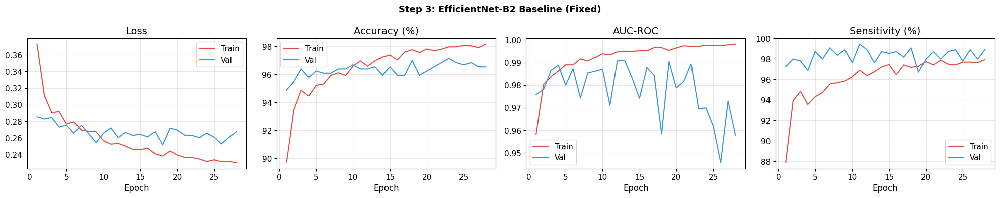

Saved: baseline_training_curves.png

Checkpoint : best_baseline_auc.pth
  Val Acc  : 96.54%
  Val AUC  : 0.9908

STEP 3 — TEST RESULTS — BASELINE (Best AUC)
  Accuracy    : 94.21%
  AUC-ROC     : 0.9905
  F1 Score    : 0.9644
  Sensitivity : 94.66%
  Specificity : 92.04%
  Confusion Matrix:
  [[104   9]
 [ 29 514]]

Checkpoint : best_baseline_acc.pth
  Val Acc  : 97.14%
  Val AUC  : 0.9697

STEP 3 — TEST RESULTS — BASELINE (Best Acc)
  Accuracy    : 97.41%
  AUC-ROC     : 0.9879
  F1 Score    : 0.9844
  Sensitivity : 98.71%
  Specificity : 91.15%
  Confusion Matrix:
  [[103  10]
 [  7 536]]


In [4]:
# ============================================================================
# STEP 3: EfficientNet-B2 Baseline
# ============================================================================

import gc
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchvision.models import efficientnet_b2, EfficientNet_B2_Weights
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.cuda.amp import GradScaler, autocast
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

os.environ['CUDA_LAUNCH_BLOCKING'] = '1'
gc.collect()
torch.cuda.empty_cache()

for i in range(torch.cuda.device_count()):
    props = torch.cuda.get_device_properties(i)
    free  = props.total_memory - torch.cuda.memory_reserved(i)
    print(f"GPU {i}: {props.name} | Free: {free/1e9:.2f} GB")


TRAIN_CONFIG = {
    'epochs'         : 50,
    'lr'             : 3e-4,
    'weight_decay'   : 3e-4,
    'min_lr'         : 1e-6,
    'patience'       : 15,
    'threshold'      : 0.5,
    'label_smoothing': 0.1,
    'device'         : 'cuda:0',
}


class EfficientNetBaseline(nn.Module):
    def __init__(self, num_classes=1, dropout=0.5):
        super().__init__()
        self.backbone = efficientnet_b2(weights=EfficientNet_B2_Weights.IMAGENET1K_V1)
        in_features   = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_features, 256),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)


class BCEWithLabelSmoothing(nn.Module):
    def __init__(self, smoothing=0.1, pos_weight=None):
        super().__init__()
        self.smoothing  = smoothing
        self.pos_weight = pos_weight

    def forward(self, inputs, targets):
        targets_smooth = targets * (1 - self.smoothing) + 0.5 * self.smoothing
        bce = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight)
        return bce(inputs, targets_smooth)


def compute_metrics(labels, preds, probs):
    cm             = confusion_matrix(labels, preds)
    tn, fp, fn, tp = cm.ravel()
    return {
        'accuracy'   : accuracy_score(labels, preds),
        'f1'         : f1_score(labels, preds, zero_division=0),
        'auc'        : roc_auc_score(labels, probs),
        'sensitivity': tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        'specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        'cm'         : cm,
    }


def run_epoch(model, loader, optimizer, criterion, scaler, device, training=True):
    model.train() if training else model.eval()
    total_loss                       = 0.0
    all_labels, all_preds, all_probs = [], [], []

    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.float().to(device, non_blocking=True).unsqueeze(1)

            if training:
                optimizer.zero_grad()

            with autocast():
                outputs = model(images)
                loss    = criterion(outputs, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item()
            probs = torch.sigmoid(outputs).detach().cpu().numpy().flatten()
            preds = (probs >= TRAIN_CONFIG['threshold']).astype(int)
            labs  = labels.detach().cpu().numpy().flatten().astype(int)

            all_probs.extend(probs)
            all_preds.extend(preds)
            all_labels.extend(labs)

    metrics         = compute_metrics(all_labels, all_preds, all_probs)
    metrics['loss'] = total_loss / len(loader)
    return metrics


def train_baseline(datasets, dataloaders, config):
    device = torch.device(config['device'])
    print(f"Device : {device}")
    print(f"GPU    : {torch.cuda.get_device_name(device)}")
    print("=" * 70)
    print("STEP 3: EfficientNet-B2 Baseline")
    print("=" * 70)
    print(f"  Dropout        : 0.5 + 0.3")
    print(f"  Weight decay   : {config['weight_decay']}")
    print(f"  Label smoothing: {config['label_smoothing']}")

    gc.collect()
    torch.cuda.empty_cache()

    model     = EfficientNetBaseline(num_classes=1, dropout=0.5).to(device)
    optimizer = AdamW(
        model.parameters(),
        lr=config['lr'],
        weight_decay=config['weight_decay']
    )
    scheduler = CosineAnnealingLR(
        optimizer,
        T_max=config['epochs'],
        eta_min=config['min_lr']
    )
    criterion = BCEWithLabelSmoothing(smoothing=config['label_smoothing'])
    scaler    = GradScaler()

    best_auc     = 0.0
    best_acc     = 0.0
    patience_ctr = 0
    history      = {'train': [], 'val': []}

    print(f"\n{'Ep':>4} {'TLoss':>7} {'TAcc':>7} {'TAUC':>7} "
          f"{'VLoss':>7} {'VAcc':>7} {'VAUC':>7} {'VF1':>7} "
          f"{'VSens':>7} {'Save':>8}")
    print("-" * 76)

    for epoch in range(1, config['epochs'] + 1):
        train_m = run_epoch(
            model, dataloaders['train'],
            optimizer, criterion, scaler, device, training=True
        )
        val_m = run_epoch(
            model, dataloaders['validation'],
            None, criterion, None, device, training=False
        )
        scheduler.step()

        history['train'].append(train_m)
        history['val'].append(val_m)

        saved = []

        if val_m['auc'] > best_auc:
            best_auc     = val_m['auc']
            patience_ctr = 0
            torch.save(
                {
                    'epoch'      : epoch,
                    'model_state': model.state_dict(),
                    'val_acc'    : val_m['accuracy'],
                    'val_auc'    : val_m['auc'],
                    'val_f1'     : val_m['f1'],
                    'val_sens'   : val_m['sensitivity'],
                },
                'best_baseline_auc.pth'
            )
            saved.append('AUC')
        else:
            patience_ctr += 1
            if patience_ctr >= config['patience']:
                print(f"\nEarly stopping at epoch {epoch}")
                break

        if val_m['accuracy'] > best_acc:
            best_acc = val_m['accuracy']
            torch.save(
                {
                    'epoch'      : epoch,
                    'model_state': model.state_dict(),
                    'val_acc'    : val_m['accuracy'],
                    'val_auc'    : val_m['auc'],
                    'val_f1'     : val_m['f1'],
                    'val_sens'   : val_m['sensitivity'],
                },
                'best_baseline_acc.pth'
            )
            saved.append('ACC')

        save_str = '+'.join(saved) if saved else ''

        print(f"{epoch:>4} "
              f"{train_m['loss']:>7.4f} "
              f"{train_m['accuracy']*100:>6.2f}% "
              f"{train_m['auc']:>7.4f} "
              f"{val_m['loss']:>7.4f} "
              f"{val_m['accuracy']*100:>6.2f}% "
              f"{val_m['auc']:>7.4f} "
              f"{val_m['f1']:>7.4f} "
              f"{val_m['sensitivity']*100:>6.2f}% "
              f"{save_str:>8}")

    print(f"\nBest Val AUC : {best_auc:.4f}")
    print(f"Best Val Acc : {best_acc*100:.2f}%")
    return model, history


def evaluate_test(model_path, dataloaders, config, label=''):
    device = torch.device(config['device'])
    model  = EfficientNetBaseline(num_classes=1, dropout=0.5).to(device)
    ckpt   = torch.load(model_path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt['model_state'])

    print(f"\nCheckpoint : {model_path}")
    print(f"  Val Acc  : {ckpt['val_acc']*100:.2f}%")
    print(f"  Val AUC  : {ckpt['val_auc']:.4f}")

    criterion = BCEWithLabelSmoothing(smoothing=config['label_smoothing'])
    test_m    = run_epoch(
        model, dataloaders['test'],
        None, criterion, None, device, training=False
    )

    title = f"BASELINE ({label})" if label else "BASELINE"
    print("\n" + "=" * 70)
    print(f"STEP 3 — TEST RESULTS — {title}")
    print("=" * 70)
    print(f"  Accuracy    : {test_m['accuracy']*100:.2f}%")
    print(f"  AUC-ROC     : {test_m['auc']:.4f}")
    print(f"  F1 Score    : {test_m['f1']:.4f}")
    print(f"  Sensitivity : {test_m['sensitivity']*100:.2f}%")
    print(f"  Specificity : {test_m['specificity']*100:.2f}%")
    print(f"  Confusion Matrix:\n  {test_m['cm']}")
    return test_m


def plot_training_curves(history):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle("Step 3: EfficientNet-B2 Baseline (Fixed)",
                 fontsize=13, fontweight='bold')

    epochs          = range(1, len(history['train']) + 1)
    metrics_to_plot = [
        ('loss',        'Loss'),
        ('accuracy',    'Accuracy (%)'),
        ('auc',         'AUC-ROC'),
        ('sensitivity', 'Sensitivity (%)'),
    ]

    for ax, (key, title) in zip(axes, metrics_to_plot):
        scale = 100 if key in ('accuracy', 'sensitivity') else 1
        ax.plot(epochs,
                [m[key] * scale for m in history['train']],
                label='Train', color='#E74C3C')
        ax.plot(epochs,
                [m[key] * scale for m in history['val']],
                label='Val', color='#3498DB')
        ax.set_title(title)
        ax.set_xlabel('Epoch')
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('baseline_training_curves.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: baseline_training_curves.png")


# ============================================================================
# RUN
# ============================================================================

model, history = train_baseline(datasets, dataloaders, TRAIN_CONFIG)
plot_training_curves(history)

test_metrics_auc = evaluate_test('best_baseline_auc.pth', dataloaders, TRAIN_CONFIG, label='Best AUC')
test_metrics_acc = evaluate_test('best_baseline_acc.pth', dataloaders, TRAIN_CONFIG, label='Best Acc')
test_metrics = test_metrics_auc  # default

GPU 0: Tesla T4 | Free: 15.38 GB
GPU 1: Tesla T4 | Free: 15.42 GB
Device : cuda:1
GPU    : Tesla T4
STEP 4: DenseNet121 
  Parameters: 7.22M

  Ep   TLoss    TAcc    TAUC   VLoss    VAcc    VAUC     VF1   VSens     Save
----------------------------------------------------------------------------
   1  0.3729  89.64%  0.9582  0.2879  94.44%  0.9726  0.9669  98.72%  AUC+ACC
   2  0.3299  92.42%  0.9747  0.3260  94.14%  0.9742  0.9637  94.53%      AUC
   3  0.3148  93.35%  0.9795  0.2820  95.19%  0.9759  0.9714  99.09%  AUC+ACC
   4  0.3052  94.10%  0.9820  0.2842  95.79%  0.9822  0.9747  98.36%  AUC+ACC
   5  0.2905  94.66%  0.9876  0.2832  95.34%  0.9752  0.9722  99.09%         
   6  0.2903  94.51%  0.9870  0.2715  95.34%  0.9818  0.9720  98.36%         
   7  0.2847  95.08%  0.9879  0.3039  93.23%  0.9809  0.9581  93.80%         
   8  0.2787  95.31%  0.9898  0.2782  95.49%  0.9750  0.9728  97.99%         
   9  0.2757  95.62%  0.9898  0.2996  94.29%  0.9723  0.9664  99.64%         
 

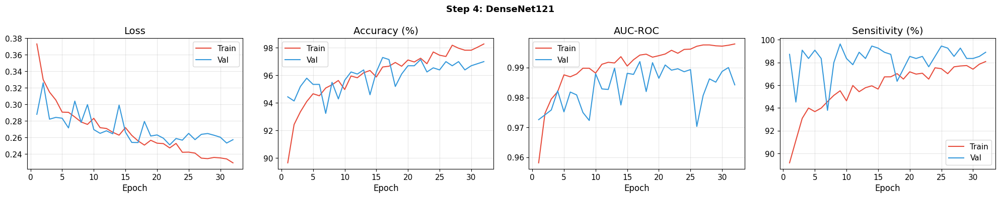

Saved: densenet_training_curves.png

Checkpoint : best_densenet_auc.pth
  Val Acc  : 97.14%
  Val AUC  : 0.9920

STEP 5A — TEST RESULTS — DenseNet121 (Best AUC)
  Accuracy    : 95.43%
  AUC-ROC     : 0.9855
  F1 Score    : 0.9722
  Sensitivity : 96.69%
  Specificity : 89.38%
  Confusion Matrix:
  [[101  12]
 [ 18 525]]

Checkpoint : best_densenet_acc.pth
  Val Acc  : 97.29%
  Val AUC  : 0.9878

STEP 5A — TEST RESULTS — DenseNet121 (Best Acc)
  Accuracy    : 95.58%
  AUC-ROC     : 0.9894
  F1 Score    : 0.9732
  Sensitivity : 96.87%
  Specificity : 89.38%
  Confusion Matrix:
  [[101  12]
 [ 17 526]]


In [11]:
# ============================================================================
# STEP 4: DenseNet121
# ============================================================================

import gc
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchvision.models import densenet121, DenseNet121_Weights
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.cuda.amp import GradScaler, autocast
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

os.environ['CUDA_LAUNCH_BLOCKING'] = '1'
gc.collect()
torch.cuda.empty_cache()

for i in range(torch.cuda.device_count()):
    props = torch.cuda.get_device_properties(i)
    free  = props.total_memory - torch.cuda.memory_reserved(i)
    print(f"GPU {i}: {props.name} | Free: {free/1e9:.2f} GB")


DENSENET_CONFIG = {
    'epochs'         : 50,
    'lr'             : 2e-4,
    'weight_decay'   : 3e-4,
    'min_lr'         : 1e-6,
    'patience'       : 15,
    'threshold'      : 0.5,
    'label_smoothing': 0.1,
    'device'         : 'cuda:1',
}


class DenseNetTeacher(nn.Module):
    def __init__(self, num_classes=1, dropout=0.5):
        super().__init__()
        backbone    = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1)
        in_features = backbone.classifier.in_features
        backbone.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_features, 256),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
        self.model = backbone

    def forward(self, x):
        return self.model(x)


class BCEWithLabelSmoothing(nn.Module):
    def __init__(self, smoothing=0.1):
        super().__init__()
        self.smoothing = smoothing

    def forward(self, inputs, targets):
        targets_smooth = targets * (1 - self.smoothing) + 0.5 * self.smoothing
        return nn.functional.binary_cross_entropy_with_logits(
            inputs, targets_smooth
        )


def compute_metrics(labels, preds, probs):
    cm             = confusion_matrix(labels, preds)
    tn, fp, fn, tp = cm.ravel()
    return {
        'accuracy'   : accuracy_score(labels, preds),
        'f1'         : f1_score(labels, preds, zero_division=0),
        'auc'        : roc_auc_score(labels, probs),
        'sensitivity': tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        'specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        'cm'         : cm,
    }


def run_epoch(model, loader, optimizer, criterion,
              scaler, device, threshold=0.5, training=True):
    model.train() if training else model.eval()
    total_loss                       = 0.0
    all_labels, all_preds, all_probs = [], [], []

    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.float().to(device, non_blocking=True).unsqueeze(1)

            if training:
                optimizer.zero_grad()

            with autocast():
                outputs = model(images)
                loss    = criterion(outputs, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item()
            probs = torch.sigmoid(outputs).detach().cpu().numpy().flatten()
            preds = (probs >= threshold).astype(int)
            labs  = labels.detach().cpu().numpy().flatten().astype(int)

            all_probs.extend(probs)
            all_preds.extend(preds)
            all_labels.extend(labs)

    metrics         = compute_metrics(all_labels, all_preds, all_probs)
    metrics['loss'] = total_loss / len(loader)
    return metrics


def train_densenet(datasets, dataloaders, config):
    device = torch.device(config['device'])
    print(f"Device : {device}")
    print(f"GPU    : {torch.cuda.get_device_name(device)}")
    print("=" * 70)
    print("STEP 4: DenseNet121 ")
    print("=" * 70)

    gc.collect()
    torch.cuda.empty_cache()

    model     = DenseNetTeacher(num_classes=1, dropout=0.5).to(device)
    optimizer = AdamW(
        model.parameters(),
        lr           = config['lr'],
        weight_decay = config['weight_decay']
    )
    scheduler = CosineAnnealingLR(
        optimizer,
        T_max   = config['epochs'],
        eta_min = config['min_lr']
    )
    criterion = BCEWithLabelSmoothing(smoothing=config['label_smoothing'])
    scaler    = GradScaler()

    total_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"  Parameters: {total_params:.2f}M\n")

    best_auc     = 0.0
    best_acc     = 0.0
    patience_ctr = 0
    history      = {'train': [], 'val': []}

    print(f"{'Ep':>4} {'TLoss':>7} {'TAcc':>7} {'TAUC':>7} "
          f"{'VLoss':>7} {'VAcc':>7} {'VAUC':>7} {'VF1':>7} "
          f"{'VSens':>7} {'Save':>8}")
    print("-" * 76)

    for epoch in range(1, config['epochs'] + 1):
        train_m = run_epoch(
            model, dataloaders['train'],
            optimizer, criterion, scaler, device,
            threshold=config['threshold'], training=True
        )
        val_m = run_epoch(
            model, dataloaders['validation'],
            None, criterion, None, device,
            threshold=config['threshold'], training=False
        )
        scheduler.step()

        history['train'].append(train_m)
        history['val'].append(val_m)

        saved = []

        if val_m['auc'] > best_auc:
            best_auc     = val_m['auc']
            patience_ctr = 0
            torch.save(
                {
                    'epoch'      : epoch,
                    'model_state': model.state_dict(),
                    'val_acc'    : val_m['accuracy'],
                    'val_auc'    : val_m['auc'],
                    'val_f1'     : val_m['f1'],
                    'val_sens'   : val_m['sensitivity'],
                },
                'best_densenet_auc.pth'
            )
            saved.append('AUC')
        else:
            patience_ctr += 1
            if patience_ctr >= config['patience']:
                print(f"\nEarly stopping at epoch {epoch}")
                break

        if val_m['accuracy'] > best_acc:
            best_acc = val_m['accuracy']
            torch.save(
                {
                    'epoch'      : epoch,
                    'model_state': model.state_dict(),
                    'val_acc'    : val_m['accuracy'],
                    'val_auc'    : val_m['auc'],
                    'val_f1'     : val_m['f1'],
                    'val_sens'   : val_m['sensitivity'],
                },
                'best_densenet_acc.pth'
            )
            saved.append('ACC')

        save_str = '+'.join(saved) if saved else ''

        print(f"{epoch:>4} "
              f"{train_m['loss']:>7.4f} "
              f"{train_m['accuracy']*100:>6.2f}% "
              f"{train_m['auc']:>7.4f} "
              f"{val_m['loss']:>7.4f} "
              f"{val_m['accuracy']*100:>6.2f}% "
              f"{val_m['auc']:>7.4f} "
              f"{val_m['f1']:>7.4f} "
              f"{val_m['sensitivity']*100:>6.2f}% "
              f"{save_str:>8}")

    print(f"\nBest Val AUC : {best_auc:.4f}")
    print(f"Best Val Acc : {best_acc*100:.2f}%")
    return model, history


def evaluate_test_densenet(model_path, dataloaders, config, label=''):
    device = torch.device(config['device'])
    model  = DenseNetTeacher(num_classes=1, dropout=0.5).to(device)
    ckpt   = torch.load(model_path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt['model_state'])

    print(f"\nCheckpoint : {model_path}")
    print(f"  Val Acc  : {ckpt['val_acc']*100:.2f}%")
    print(f"  Val AUC  : {ckpt['val_auc']:.4f}")

    criterion = BCEWithLabelSmoothing(smoothing=config['label_smoothing'])
    test_m    = run_epoch(
        model, dataloaders['test'],
        None, criterion, None, device,
        threshold=config['threshold'], training=False
    )

    title = f"DenseNet121 ({label})" if label else "DenseNet121"
    print("\n" + "=" * 70)
    print(f"STEP 5A — TEST RESULTS — {title}")
    print("=" * 70)
    print(f"  Accuracy    : {test_m['accuracy']*100:.2f}%")
    print(f"  AUC-ROC     : {test_m['auc']:.4f}")
    print(f"  F1 Score    : {test_m['f1']:.4f}")
    print(f"  Sensitivity : {test_m['sensitivity']*100:.2f}%")
    print(f"  Specificity : {test_m['specificity']*100:.2f}%")
    print(f"  Confusion Matrix:\n  {test_m['cm']}")
    return test_m


def plot_densenet_curves(history):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    fig.suptitle("Step 4: DenseNet121",
                 fontsize=13, fontweight='bold')

    epochs          = range(1, len(history['train']) + 1)
    metrics_to_plot = [
        ('loss',        'Loss'),
        ('accuracy',    'Accuracy (%)'),
        ('auc',         'AUC-ROC'),
        ('sensitivity', 'Sensitivity (%)'),
    ]

    for ax, (key, title) in zip(axes, metrics_to_plot):
        scale = 100 if key in ('accuracy', 'sensitivity') else 1
        ax.plot(epochs,
                [m[key] * scale for m in history['train']],
                label='Train', color='#E74C3C')
        ax.plot(epochs,
                [m[key] * scale for m in history['val']],
                label='Val', color='#3498DB')
        ax.set_title(title)
        ax.set_xlabel('Epoch')
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('densenet_training_curves.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: densenet_training_curves.png")


# ============================================================================
# RUN
# ============================================================================

densenet_model, densenet_history = train_densenet(
    datasets, dataloaders, DENSENET_CONFIG
)
plot_densenet_curves(densenet_history)

densenet_test_auc = evaluate_test_densenet(
    'best_densenet_auc.pth', dataloaders, DENSENET_CONFIG, label='Best AUC'
)
densenet_test_acc = evaluate_test_densenet(
    'best_densenet_acc.pth', dataloaders, DENSENET_CONFIG, label='Best Acc'
)

In [17]:
import torch
import numpy as np
from torch.cuda.amp import autocast

device = torch.device('cuda:0')

# Load both models
eff_model = EfficientNetBaseline(num_classes=1, dropout=0.5).to(device)
ckpt = torch.load('best_baseline_acc.pth', map_location=device, weights_only=False)
eff_model.load_state_dict(ckpt['model_state'])
eff_model.eval()

dense_model = DenseNetTeacher(num_classes=1, dropout=0.5).to(device)
ckpt = torch.load('best_densenet_acc.pth', map_location=device, weights_only=False)
dense_model.load_state_dict(ckpt['model_state'])
dense_model.eval()

# Get all predictions
eff_probs   = []
dense_probs = []
all_labels  = []

with torch.no_grad():
    for images, labels in dataloaders['test']:
        images = images.to(device)
        with autocast():
            ep = torch.sigmoid(eff_model(images)).cpu().numpy().flatten()
            dp = torch.sigmoid(dense_model(images)).cpu().numpy().flatten()
        eff_probs.extend(ep)
        dense_probs.extend(dp)
        all_labels.extend(labels.numpy())

eff_probs   = np.array(eff_probs)
dense_probs = np.array(dense_probs)
all_labels  = np.array(all_labels)

# Best threshold for each
eff_preds   = (eff_probs >= 0.5).astype(int)
dense_preds = (dense_probs >= 0.5).astype(int)

eff_wrong   = np.where(eff_preds != all_labels)[0]
dense_wrong = np.where(dense_preds != all_labels)[0]

both_wrong  = np.intersect1d(eff_wrong, dense_wrong)
only_eff_wrong   = np.setdiff1d(eff_wrong, dense_wrong)
only_dense_wrong = np.setdiff1d(dense_wrong, eff_wrong)

agree       = np.where(eff_preds == dense_preds)[0]
disagree    = np.where(eff_preds != dense_preds)[0]

print("=" * 70)
print("ERROR ANALYSIS")
print("=" * 70)
print(f"\nTotal test images     : {len(all_labels)}")
print(f"EfficientNet wrong    : {len(eff_wrong)}")
print(f"DenseNet wrong        : {len(dense_wrong)}")
print(f"Both wrong (same img) : {len(both_wrong)}")
print(f"Only EfficientNet wrong: {len(only_eff_wrong)}")
print(f"Only DenseNet wrong   : {len(only_dense_wrong)}")
print(f"\nModels agree          : {len(agree)}")
print(f"Models disagree       : {len(disagree)}")

# Disagreement analysis
print(f"\nDISAGREEMENT CASES ({len(disagree)}):")
print(f"  EfficientNet correct: {sum(eff_preds[disagree] == all_labels[disagree])}")
print(f"  DenseNet correct    : {sum(dense_preds[disagree] == all_labels[disagree])}")

# Agreement accuracy
agree_correct = sum(eff_preds[agree] == all_labels[agree])
print(f"\nAGREEMENT CASES ({len(agree)}):")
print(f"  Correct : {agree_correct}")
print(f"  Wrong   : {len(agree) - agree_correct}")
print(f"  Accuracy: {agree_correct/len(agree)*100:.2f}%")

# If we trust agreement and fix disagreement perfectly
perfect_disagree = len(disagree)
best_possible = agree_correct + perfect_disagree
print(f"\nBEST POSSIBLE (if we fix all disagreements):")
print(f"  {best_possible}/{len(all_labels)} = {best_possible/len(all_labels)*100:.2f}%")

ERROR ANALYSIS

Total test images     : 656
EfficientNet wrong    : 17
DenseNet wrong        : 29
Both wrong (same img) : 5
Only EfficientNet wrong: 12
Only DenseNet wrong   : 24

Models agree          : 620
Models disagree       : 36

DISAGREEMENT CASES (36):
  EfficientNet correct: 24
  DenseNet correct    : 12

AGREEMENT CASES (620):
  Correct : 615
  Wrong   : 5
  Accuracy: 99.19%

BEST POSSIBLE (if we fix all disagreements):
  651/656 = 99.24%


In [27]:
# ============================================================================
# STEP 6: Confidence-Aware Referee Network
# ============================================================================

import torch
import numpy as np
from torch.cuda.amp import autocast
from sklearn.metrics import (accuracy_score, f1_score,
                             roc_auc_score, confusion_matrix)

device = torch.device('cuda:0')

print("=" * 70)
print("STEP 6: Confidence-Aware Referee Network")
print("=" * 70)

# ============================================================
# STEP 1: Extract predictions + physics from ALL splits
# ============================================================

def extract_referee_data(dataloaders, eff_model, dense_model,
                         physics_extractor, device):
    data = {}

    for split in ['train', 'validation', 'test']:
        eff_probs_list   = []
        dense_probs_list = []
        physics_list     = []
        labels_list      = []

        eff_model.eval()
        dense_model.eval()

        with torch.no_grad():
            for images, labels in dataloaders[split]:
                images = images.to(device)

                with autocast():
                    ep = torch.sigmoid(eff_model(images)).cpu().numpy().flatten()
                    dp = torch.sigmoid(dense_model(images)).cpu().numpy().flatten()

                pf = physics_extractor.extract(images)

                eff_probs_list.extend(ep)
                dense_probs_list.extend(dp)
                physics_list.append(pf)
                labels_list.extend(labels.numpy())

        eff_probs   = np.array(eff_probs_list)
        dense_probs = np.array(dense_probs_list)
        physics     = np.concatenate(physics_list, axis=0)
        labels      = np.array(labels_list)

        # Referee features
        conf_gap = np.abs(eff_probs - dense_probs)
        eff_conf = np.abs(eff_probs - 0.5) * 2
        dense_conf = np.abs(dense_probs - 0.5) * 2

        features = np.column_stack([
            eff_probs,        # EfficientNet probability
            dense_probs,      # DenseNet probability
            conf_gap,         # Confidence gap
            eff_conf,         # EfficientNet confidence
            dense_conf,       # DenseNet confidence
            physics           # 5 physics features
        ])

        # Agreement / disagreement mask
        eff_preds   = (eff_probs >= 0.5).astype(int)
        dense_preds = (dense_probs >= 0.5).astype(int)
        agree_mask  = (eff_preds == dense_preds)

        data[split] = {
            'features'    : features,
            'labels'      : labels,
            'eff_probs'   : eff_probs,
            'dense_probs' : dense_probs,
            'eff_preds'   : eff_preds,
            'dense_preds' : dense_preds,
            'agree_mask'  : agree_mask,
        }

        n_agree    = agree_mask.sum()
        n_disagree = (~agree_mask).sum()
        print(f"  {split:>12}: {len(labels)} images | "
              f"Agree: {n_agree} | Disagree: {n_disagree}")

    return data


# Load models
eff_model = EfficientNetBaseline(num_classes=1, dropout=0.5).to(device)
ckpt = torch.load('best_baseline_acc.pth',
                   map_location=device, weights_only=False)
eff_model.load_state_dict(ckpt['model_state'])
eff_model.eval()

dense_model = DenseNetTeacher(num_classes=1, dropout=0.5).to(device)
ckpt = torch.load('best_densenet_acc.pth',
                   map_location=device, weights_only=False)
dense_model.load_state_dict(ckpt['model_state'])
dense_model.eval()

physics_extractor = PhysicsFeatureExtractor(var_kernel=15)

print("\nExtracting referee data...")
referee_data = extract_referee_data(
    dataloaders, eff_model, dense_model,
    physics_extractor, device
)


# ============================================================
# STEP 2: Train Referee on DISAGREEMENT cases only
# ============================================================

print("\n" + "-" * 70)
print("Training Referee on Disagreement Cases")
print("-" * 70)

# Train referee on ALL data (agreement + disagreement)
# কিন্তু referee শুধু disagreement এ use হবে
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

X_train = referee_data['train']['features']
y_train = referee_data['train']['labels']
X_val   = referee_data['validation']['features']
y_val   = referee_data['validation']['labels']
X_test  = referee_data['test']['features']
y_test  = referee_data['test']['labels']

# Standardize
from sklearn.preprocessing import StandardScaler
scaler  = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Train multiple referees
referees = {}

# Logistic Regression
lr = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
lr.fit(X_train_s, y_train)
referees['LR'] = lr

# Gradient Boosting
gb = GradientBoostingClassifier(
    n_estimators=200, max_depth=4,
    learning_rate=0.05, subsample=0.8,
    random_state=42
)
gb.fit(X_train_s, y_train)
referees['GB'] = gb

# SVM
from sklearn.svm import SVC
svm = SVC(kernel='rbf', C=10.0, gamma='scale',
          probability=True, random_state=42)
svm.fit(X_train_s, y_train)
referees['SVM'] = svm

# Random Forest
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators=200, max_depth=8,
    min_samples_leaf=3, random_state=42
)
rf.fit(X_train_s, y_train)
referees['RF'] = rf

# XGBoost
try:
    from xgboost import XGBClassifier
    xgb = XGBClassifier(
        n_estimators=200, max_depth=4,
        learning_rate=0.05, subsample=0.8,
        random_state=42, eval_metric='logloss',
        use_label_encoder=False
    )
    xgb.fit(X_train_s, y_train)
    referees['XGB'] = xgb
except ImportError:
    pass

# LightGBM
try:
    from lightgbm import LGBMClassifier
    lgb = LGBMClassifier(
        n_estimators=200, max_depth=4,
        learning_rate=0.05, subsample=0.8,
        random_state=42, verbose=-1
    )
    lgb.fit(X_train_s, y_train)
    referees['LGB'] = lgb
except ImportError:
    pass


# ============================================================
# STEP 3: Evaluate — Agreement uses CNN, Disagreement uses Referee
# ============================================================

print("\n" + "-" * 70)
print("Referee-Assisted Results on Test Set")
print("-" * 70)

test_data = referee_data['test']
agree     = test_data['agree_mask']
disagree  = ~agree

# Agreement cases — use EfficientNet prediction (stronger model)
agree_preds  = test_data['eff_preds'][agree]
agree_labels = test_data['labels'][agree]
agree_correct = (agree_preds == agree_labels).sum()

print(f"\nAgreement cases  : {agree.sum()}")
print(f"  Correct        : {agree_correct}")
print(f"  Accuracy       : {agree_correct/agree.sum()*100:.2f}%")

print(f"\nDisagreement cases: {disagree.sum()}")

best_total_acc  = 0.0
best_referee    = ''
best_auc        = 0.0

for name, referee in referees.items():
    # Referee predicts disagreement cases
    dis_features = X_test_s[disagree]
    dis_labels   = test_data['labels'][disagree]
    dis_preds    = referee.predict(dis_features)
    dis_correct  = (dis_preds == dis_labels).sum()

    # Combine
    total_correct = agree_correct + dis_correct
    total_acc     = total_correct / len(y_test)

    # Full test probs for AUC
    full_probs = np.zeros(len(y_test))
    full_probs[agree] = test_data['eff_probs'][agree]
    if hasattr(referee, 'predict_proba'):
        full_probs[disagree] = referee.predict_proba(dis_features)[:, 1]
    else:
        full_probs[disagree] = referee.decision_function(dis_features)

    full_preds = np.zeros(len(y_test), dtype=int)
    full_preds[agree]    = test_data['eff_preds'][agree]
    full_preds[disagree] = dis_preds

    cm   = confusion_matrix(y_test, full_preds)
    tn, fp, fn, tp = cm.ravel()
    auc  = roc_auc_score(y_test, full_probs)
    f1   = f1_score(y_test, full_preds)
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0

    marker = " ***" if total_acc > best_total_acc else ""
    if total_acc > best_total_acc:
        best_total_acc = total_acc
        best_referee   = name
        best_auc       = auc 

    print(f"\n  Referee: {name}")
    print(f"    Disagree correct : {dis_correct}/{disagree.sum()}")
    print(f"    Total Accuracy   : {total_acc*100:.2f}%{marker}")
    print(f"    AUC-ROC          : {auc:.4f}")
    print(f"    F1               : {f1:.4f}")
    print(f"    Sensitivity      : {sens*100:.2f}%")
    print(f"    Specificity      : {spec*100:.2f}%")
    print(f"    CM               : {cm}")

print(f"\nBest Referee: {best_referee} ({best_total_acc*100:.2f}%)")


# ============================================================
# FINAL COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("FINAL COMPARISON — ALL APPROACHES")
print("=" * 70)
print(f"\n  {'Method':<40} {'Test Acc':>10} {'AUC':>10}")
print("  " + "-" * 60)

print(f"  {'EfficientNet-B2 (Best ACC)':<40} "
      f"{test_metrics_acc['accuracy']*100:>9.2f}% "
      f"{test_metrics_acc['auc']:>10.4f}")

print(f"  {'DenseNet121 (Best ACC)':<40} "
      f"{densenet_test_acc['accuracy']*100:>9.2f}% "
      f"{densenet_test_acc['auc']:>10.4f}")

print(f"  {f'Referee-Assisted ({best_referee})':<40} "
      f"{best_total_acc*100:>9.2f}% "
      f"{best_auc:>10.4f}")

STEP 6: Confidence-Aware Referee Network

Extracting referee data...
         train: 5504 images | Agree: 5326 | Disagree: 178
    validation: 665 images | Agree: 654 | Disagree: 11
          test: 656 images | Agree: 620 | Disagree: 36

----------------------------------------------------------------------
Training Referee on Disagreement Cases
----------------------------------------------------------------------

----------------------------------------------------------------------
Referee-Assisted Results on Test Set
----------------------------------------------------------------------

Agreement cases  : 620
  Correct        : 615
  Accuracy       : 99.19%

Disagreement cases: 36

  Referee: LR
    Disagree correct : 28/36
    Total Accuracy   : 98.02% ***
    AUC-ROC          : 0.9830
    F1               : 0.9881
    Sensitivity      : 99.08%
    Specificity      : 92.92%
    CM               : [[105   8]
 [  5 538]]

  Referee: GB
    Disagree correct : 29/36
    Total Accura

STEP 7: Ablation Study + XAI

----------------------------------------------------------------------
PART A: ABLATION STUDY
----------------------------------------------------------------------

Running ablation experiments...

ABLATION STUDY RESULTS

  Experiment                                         Acc      AUC       F1     Sens     Spec
  -----------------------------------------------------------------------------
  A. EfficientNet-B2 alone                        97.41%   0.9879   0.9844   98.71%   91.15%
  B. DenseNet121 alone                            95.58%   0.9894   0.9732   96.87%   89.38%
  C. Referee (EfficientNet only, no Dense)        97.41%   0.9879   0.9844   98.71%   91.15%
  D. Referee (no physics features)                97.87%   0.9822   0.9872   99.08%   92.04%
  E. Referee (full framework)                     98.17%   0.9823   0.9890   99.26%   92.92%

  Contributions:
    DenseNet diversity:   +0.76%
    Physics features:     +0.30%
    Full framework gain: 

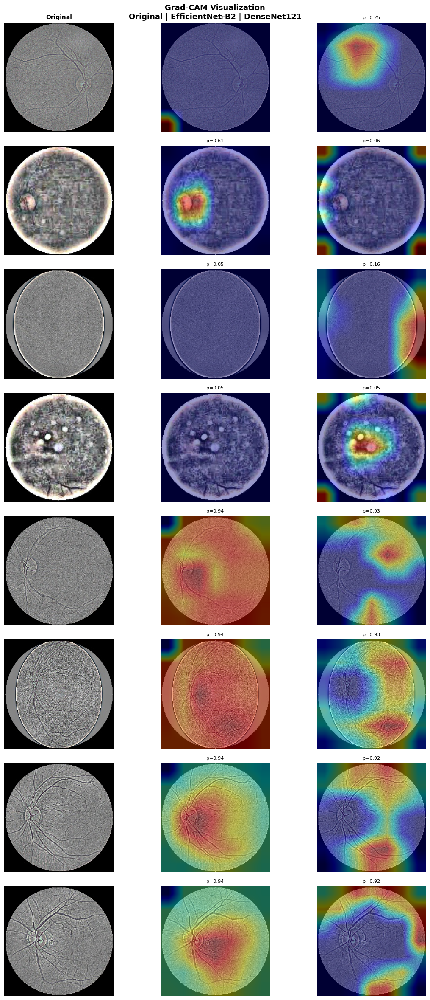

Saved: gradcam_visualization.png

STEP 7 SUMMARY

  Ablation Study:
    A. EfficientNet alone:              97.41%
    B. DenseNet alone:                  95.58%
    C. Referee (EfficientNet only):     97.41%
    D. Referee (no physics):            97.87%
    E. Referee (full framework):        98.17%

    DenseNet diversity contribution:    +0.76%
    Physics feature contribution:       +0.30%
    Total framework gain over baseline: +0.76%



In [30]:
# ============================================================================
# STEP 7: Ablation Study + XAI (Grad-CAM)
# ============================================================================

import gc
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

device = torch.device('cuda:0')

print("=" * 70)
print("STEP 7: Ablation Study + XAI")
print("=" * 70)


# ============================================================================
# PART A: ABLATION STUDY
# ============================================================================

print("\n" + "-" * 70)
print("PART A: ABLATION STUDY")
print("-" * 70)


def run_single_model_test(model, dataloaders, device, threshold=0.5):
    model.eval()
    all_probs, all_labels = [], []

    with torch.no_grad():
        for images, labels in dataloaders['test']:
            images = images.to(device)
            with torch.cuda.amp.autocast():
                probs = torch.sigmoid(model(images)).cpu().numpy().flatten()
            all_probs.extend(probs)
            all_labels.extend(labels.numpy())

    all_probs  = np.array(all_probs)
    all_labels = np.array(all_labels)
    preds      = (all_probs >= threshold).astype(int)
    cm             = confusion_matrix(all_labels, preds)
    tn, fp, fn, tp = cm.ravel()

    return {
        'accuracy'   : accuracy_score(all_labels, preds),
        'auc'        : roc_auc_score(all_labels, all_probs),
        'f1'         : f1_score(all_labels, preds, zero_division=0),
        'sensitivity': tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        'specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
    }


def referee_without_physics(referee_data):
    test_d   = referee_data['test']
    agree    = test_d['agree_mask']
    disagree = ~agree

    X_train_nop = referee_data['train']['features'][:, :5]
    y_train_nop = referee_data['train']['labels']
    X_test_nop  = test_d['features'][:, :5]

    from sklearn.preprocessing import StandardScaler
    from sklearn.ensemble import GradientBoostingClassifier

    scaler_nop    = StandardScaler()
    X_train_nop_s = scaler_nop.fit_transform(X_train_nop)
    X_test_nop_s  = scaler_nop.transform(X_test_nop)

    gb_nop = GradientBoostingClassifier(
        n_estimators=200, max_depth=4,
        learning_rate=0.05, subsample=0.8,
        random_state=42
    )
    gb_nop.fit(X_train_nop_s, y_train_nop)

    agree_correct = (test_d['eff_preds'][agree] == test_d['labels'][agree]).sum()
    dis_preds     = gb_nop.predict(X_test_nop_s[disagree])
    dis_correct   = (dis_preds == test_d['labels'][disagree]).sum()
    total_acc     = (agree_correct + dis_correct) / len(test_d['labels'])

    full_preds = np.zeros(len(test_d['labels']), dtype=int)
    full_preds[agree]    = test_d['eff_preds'][agree]
    full_preds[disagree] = dis_preds

    full_probs = np.zeros(len(test_d['labels']))
    full_probs[agree]    = test_d['eff_probs'][agree]
    full_probs[disagree] = gb_nop.predict_proba(X_test_nop_s[disagree])[:, 1]

    cm             = confusion_matrix(test_d['labels'], full_preds)
    tn, fp, fn, tp = cm.ravel()

    return {
        'accuracy'   : total_acc,
        'auc'        : roc_auc_score(test_d['labels'], full_probs),
        'f1'         : f1_score(test_d['labels'], full_preds, zero_division=0),
        'sensitivity': tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        'specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
    }


def referee_eff_only(referee_data):
    test_d     = referee_data['test']
    full_preds = test_d['eff_preds'].copy()
    cm             = confusion_matrix(test_d['labels'], full_preds)
    tn, fp, fn, tp = cm.ravel()
    return {
        'accuracy'   : accuracy_score(test_d['labels'], full_preds),
        'auc'        : roc_auc_score(test_d['labels'], test_d['eff_probs']),
        'f1'         : f1_score(test_d['labels'], full_preds, zero_division=0),
        'sensitivity': tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        'specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
    }


def build_ref_full(referee_data, referees, X_test_s, best_total_acc, best_auc):
    test_d    = referee_data['test']
    agree     = test_d['agree_mask']
    disagree  = ~agree

    full_preds = np.zeros(len(test_d['labels']), dtype=int)
    full_preds[agree]    = test_d['eff_preds'][agree]
    full_preds[disagree] = referees['GB'].predict(X_test_s[disagree])

    full_probs = np.zeros(len(test_d['labels']))
    full_probs[agree]    = test_d['eff_probs'][agree]
    full_probs[disagree] = referees['GB'].predict_proba(
        X_test_s[disagree]
    )[:, 1]

    cm             = confusion_matrix(test_d['labels'], full_preds)
    tn, fp, fn, tp = cm.ravel()

    return {
        'accuracy'   : best_total_acc,
        'auc'        : best_auc,
        'f1'         : f1_score(test_d['labels'], full_preds, zero_division=0),
        'sensitivity': tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        'specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
    }


# Load models
eff_model = EfficientNetBaseline(num_classes=1, dropout=0.5).to(device)
eff_model.load_state_dict(
    torch.load('best_baseline_acc.pth',
               map_location=device, weights_only=False)['model_state']
)

dense_model = DenseNetTeacher(num_classes=1, dropout=0.5).to(device)
dense_model.load_state_dict(
    torch.load('best_densenet_acc.pth',
               map_location=device, weights_only=False)['model_state']
)

print("\nRunning ablation experiments...")

abl_eff         = run_single_model_test(eff_model,   dataloaders, device)
abl_dense       = run_single_model_test(dense_model, dataloaders, device)
abl_ref_nophys  = referee_without_physics(referee_data)
abl_ref_effonly = referee_eff_only(referee_data)
abl_ref_full    = build_ref_full(
    referee_data, referees, X_test_s, best_total_acc, best_auc
)

print("\n" + "=" * 90)
print("ABLATION STUDY RESULTS")
print("=" * 90)
print(f"\n  {'Experiment':<45} {'Acc':>8} {'AUC':>8} {'F1':>8} "
      f"{'Sens':>8} {'Spec':>8}")
print("  " + "-" * 77)

ablations = [
    ("A. EfficientNet-B2 alone",                 abl_eff),
    ("B. DenseNet121 alone",                     abl_dense),
    ("C. Referee (EfficientNet only, no Dense)", abl_ref_effonly),
    ("D. Referee (no physics features)",         abl_ref_nophys),
    ("E. Referee (full framework)",              abl_ref_full),
]

for name, m in ablations:
    print(f"  {name:<45} "
          f"{m['accuracy']*100:>7.2f}% "
          f"{m['auc']:>8.4f} "
          f"{m['f1']:>8.4f} "
          f"{m['sensitivity']*100:>7.2f}% "
          f"{m['specificity']*100:>7.2f}%")

print(f"\n  Contributions:")
print(f"    DenseNet diversity:   "
      f"{(abl_ref_full['accuracy']-abl_ref_effonly['accuracy'])*100:+.2f}%")
print(f"    Physics features:     "
      f"{(abl_ref_full['accuracy']-abl_ref_nophys['accuracy'])*100:+.2f}%")
print(f"    Full framework gain:  "
      f"{(abl_ref_full['accuracy']-abl_eff['accuracy'])*100:+.2f}%")


# ============================================================================
# PART B: XAI — Grad-CAM
# ============================================================================

print("\n" + "-" * 70)
print("PART B: XAI — Grad-CAM Visualization")
print("-" * 70)


class GradCAM:
    def __init__(self, model, target_layer):
        self.model        = model
        self.target_layer = target_layer
        self.gradients    = None
        self.activations  = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def generate(self, input_tensor):
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()
        output.backward()

        weights = self.gradients.mean(dim=[2, 3], keepdim=True)
        cam     = (weights * self.activations).sum(dim=1)
        cam     = F.relu(cam)

        cam_min = cam.flatten(1).min(1)[0].view(-1, 1, 1)
        cam_max = cam.flatten(1).max(1)[0].view(-1, 1, 1)
        cam     = (cam - cam_min) / (cam_max - cam_min + 1e-8)

        return cam.cpu().numpy(), torch.sigmoid(output).item()


def overlay_gradcam(image_np, cam, alpha=0.4):
    cam_resized = cv2.resize(cam, (image_np.shape[1], image_np.shape[0]))
    heatmap     = cv2.applyColorMap(
        (cam_resized * 255).astype(np.uint8), cv2.COLORMAP_JET
    )
    heatmap     = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay     = (alpha * heatmap +
                   (1 - alpha) * image_np * 255).astype(np.uint8)
    return overlay


def get_gradcam_target_layer(model):
    if isinstance(model, EfficientNetBaseline):
        return model.backbone.features[-1]
    elif isinstance(model, DenseNetTeacher):
        return model.model.features.denseblock4


def visualize_gradcam(dataloaders, eff_model, dense_model,
                      config, device, n_samples=8):
    import albumentations as A
    from albumentations.pytorch import ToTensorV2

    samples = {'cataract': [], 'normal': []}
    test_ds = dataloaders['test'].dataset

    for idx in range(len(test_ds)):
        label    = test_ds.labels[idx]
        cls_name = 'cataract' if label == 0 else 'normal'
        if len(samples[cls_name]) < n_samples // 2:
            img_path  = test_ds.image_paths[idx]
            load_path = test_ds.path_map.get(img_path, img_path)
            samples[cls_name].append((load_path, label))
        if (len(samples['cataract']) >= n_samples // 2 and
                len(samples['normal'])   >= n_samples // 2):
            break

    all_samples = samples['cataract'] + samples['normal']

    eff_gradcam   = GradCAM(eff_model,   get_gradcam_target_layer(eff_model))
    dense_gradcam = GradCAM(dense_model, get_gradcam_target_layer(dense_model))

    transform = A.Compose([
        A.Normalize(mean=config['mean'], std=config['std']),
        ToTensorV2()
    ])

    fig, axes = plt.subplots(n_samples, 3, figsize=(12, n_samples * 3))
    fig.suptitle(
        "Grad-CAM Visualization\nOriginal | EfficientNet-B2 | DenseNet121",
        fontsize=13, fontweight='bold'
    )

    for col, title in enumerate(['Original',
                                  'EfficientNet\nGrad-CAM',
                                  'DenseNet\nGrad-CAM']):
        axes[0, col].set_title(title, fontsize=10, fontweight='bold')

    for row, (img_path, label) in enumerate(all_samples):
        img = cv2.imread(img_path)
        if img is None:
            continue
        img     = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_vis = cv2.resize(img, (224, 224))

        tensor     = transform(image=img_vis)['image'].unsqueeze(0).to(device)

        tensor_eff = tensor.clone().requires_grad_(True)
        cam_eff, prob_eff = eff_gradcam.generate(tensor_eff)
        overlay_eff = overlay_gradcam(img_vis / 255.0, cam_eff[0])

        tensor_dns = tensor.clone().requires_grad_(True)
        cam_dns, prob_dns = dense_gradcam.generate(tensor_dns)
        overlay_dns = overlay_gradcam(img_vis / 255.0, cam_dns[0])

        cls_name = 'Cataract' if label == 0 else 'Normal'
        color    = '#E74C3C'   if label == 0 else '#3498DB'

        axes[row, 0].imshow(img_vis)
        axes[row, 0].set_ylabel(cls_name, fontsize=9,
                                fontweight='bold', color=color)
        axes[row, 0].axis('off')

        axes[row, 1].imshow(overlay_eff)
        axes[row, 1].set_title(f'p={prob_eff:.2f}', fontsize=8)
        axes[row, 1].axis('off')

        axes[row, 2].imshow(overlay_dns)
        axes[row, 2].set_title(f'p={prob_dns:.2f}', fontsize=8)
        axes[row, 2].axis('off')

    plt.tight_layout()
    plt.savefig('gradcam_visualization.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: gradcam_visualization.png")


print("\nGenerating Grad-CAM visualizations...")
visualize_gradcam(dataloaders, eff_model, dense_model,
                  CONFIG, device, n_samples=8)


# ============================================================================
# STEP 7 SUMMARY
# ============================================================================

print("\n" + "=" * 70)
print("STEP 7 SUMMARY")
print("=" * 70)

print(f"""
  Ablation Study:
    A. EfficientNet alone:              {abl_eff['accuracy']*100:.2f}%
    B. DenseNet alone:                  {abl_dense['accuracy']*100:.2f}%
    C. Referee (EfficientNet only):     {abl_ref_effonly['accuracy']*100:.2f}%
    D. Referee (no physics):            {abl_ref_nophys['accuracy']*100:.2f}%
    E. Referee (full framework):        {abl_ref_full['accuracy']*100:.2f}%

    DenseNet diversity contribution:    {(abl_ref_full['accuracy']-abl_ref_effonly['accuracy'])*100:+.2f}%
    Physics feature contribution:       {(abl_ref_full['accuracy']-abl_ref_nophys['accuracy'])*100:+.2f}%
    Total framework gain over baseline: {(abl_ref_full['accuracy']-abl_eff['accuracy'])*100:+.2f}%
""")